# Otimização do ciclo de lavagem de roupa #

**Disciplina: OTM**
Aluno: Filipe Almeida Barbosa

Ideia: Como é possível organizar uma casa para que os membros dela possam lavar roupas com o menor gasto e a máxima "satisfação"?

A partir dessa pergunta, e avaliando o problema, foi constatado que ele possui 3 "dimensões" independentes, a princípio, que influenciam no resultado final.

**Primeira Dimensão : A máquina**
A máquina de lavar, independente do usuário e de sua rotina, tem uma capacidade definida e limitada, e uma curva de custos.

**Segunda Dimensão: O indivíduo**
Um indivíduo, independentemente de seu grupo, tem uma quantidade de roupas que possuí, uma velocidade de uso das roupas e uma exigência de quanto ele deseja/precisa de roupa limpa.

**Terceira Dimensão: O grupo**
Um grupo de pessoas, por sua vez, terá cada um a própria necessidade, e representará no grupo um custo específico de acordo com suas necessidades serem(ou não) atendidas.

## Que considerações adotar? ##

A primeira parte do trabalho foi perceber que informações estariam disponíveis e quais seriam considerações. Dados como eficiência das máquinas, por ex., podem ser encontrados com os próprios fabricantes ou no site do Inmetro.

### Considerações e dados adotados ###

**Dado real** = veio de uma fonte. **Assumido** = escolha arbitrária, requer refino num uso real.

| Bloco | Consideração | Valor | Tipo | Onde está no código |
|---|---|---|---|---|
| Máquina e custo | Limpeza = 1 − e^(−Z), com o índice de limpeza Z crescendo com tempo e água por kg e caindo com a máquina cheia | expoentes do tempo a = 0,25, da água por kg d = 0,5 e da lotação θ = 0,05 | **assumido** | `MODELO_LIMPEZA`|
| | Escala do modelo de limpeza (k₀) | 0,2478 | calibrado no Inmetro (0,926) | `calibrado_em(PONTO_CALIBRACAO)` |
| | Eficácia relativa das máquinas (ε) | 1,0 para todas no caso-base | **assumido** | `eficacia_relativa` |
| | Tempo máximo, limpeza mínima e carga máxima por tipo de roupa | 120/75/30 min; 0,95/0,90/0,85; 100%/100%/60% | **assumido** | `TIPOS_DE_ROUPA` |
| | Ciclo padrão das superiores (para calibrar a energia) | 75 min | **assumido** | `CICLO_PADRAO_SUPERIOR_MIN` |
| | Preço da energia | R$ 1,14 por kWh | dado (conta de luz) | `TARIFA_ENERGIA_COM_IMPOSTOS` |
| | Preço da água | R$ 16,36 por m³ | dado (tabela Águas do Rio, Região 1), **ainda não conferido numa conta real** | `TARIFA_AGUA_REAIS_POR_M3` |
| Usuário | Consumo diário constante | 2 peças por dia | **assumido** | `CONSUMO_DIARIO_PECAS` |
| | Peças por kg de roupa normal | 3,75 | **assumido** | `PECAS_POR_KG_NORMAL` |
| | Reserva de roupa limpa que dá satisfação plena (F_ref) | 5 dias de consumo (10 peças) | **assumido** | `DIAS_AUTONOMIA` |
| | Exigência com roupa limpa (κ) | 1,0 | **assumido** | `EXIGENCIA_KAPPA` |
| | Valor de um dia sem roupa limpa (p) | R$ 2 por dia | **assumido** | `VALOR_INSATISFACAO_REAIS_DIA` |
| | Desconto da programação dinâmica (γ) | 0,97 | **assumido** | `FATOR_DESCONTO` |
| Grupo | Calendário semanal que se repete, uma máquina compartilhada | 364 dias (+ 28 de aquecimento descartados) | modelagem | `DIAS_POR_ANO`, `DIAS_DE_AQUECIMENTO` |
| | Peso de cada pessoa na decisão (W) | 1,0 | **assumido** | `peso_importancia` |
| | Custo de lavar duas classes no mesmo dia (κ_c) | 0,05 | **assumido** | `PENALIDADE_COINCIDENCIA` |
| Fora do modelo | Preço de compra, espera da frontal, espaço de secagem | n/a | n/a | n/a |
| | Vida útil da máquina (só na compra) | 10 anos | **assumido** | `VIDA_UTIL_ANOS` |

Ordens de grandeza do consumo residencial de água e energia foram consultadas na literatura listada em Referências (contexto); nenhum parâmetro do modelo vem delas diretamente.


## Dimensão 0 : Preparo ##
Funções auxiliares, registro de dados utilizados, etc. É a primeira etapa, antes do código do modelo propriamente.

### Função para criar e salvar figuras ###

In [1]:


import itertools, math, time
from dataclasses import dataclass, field, replace
from typing import Optional, Callable
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize, minimize_scalar

# Aparência dos gráficos: resolução e grade leve
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})

# ---- Figuras usadas nos slides: cada uma é salva em figuras_slides/slideNN_nome.png ----
from pathlib import Path
PASTA_FIGURAS = Path("figuras_slides"); PASTA_FIGURAS.mkdir(exist_ok=True)
def salvar_figura(nome, fig=None, dpi=130):
    # salva a figura atual (ou a dada) com o nome do slide em que ela é usada
    (fig or plt.gcf()).savefig(PASTA_FIGURAS / f"{nome}.png", dpi=dpi, bbox_inches="tight")
    print(f"[figura salva] {PASTA_FIGURAS / (nome + '.png')}")

## Máquinas reais ##

Os dados utilizados foram obtidos de duas fontes:

- **Tabela oficial do Inmetro/PBE (edição 2023), lavadoras e lava-e-seca de abertura frontal.** Para cada modelo: capacidade, consumo de energia por ciclo, consumo de água por ciclo, **eficiência de lavagem** (índice do Inmetro) e **tempo do ciclo**.
- **Fichas técnicas de fabricantes e lojas** para máquinas de **abertura superior** (comuns no Brasil). Utilizou-se valores **declarados pelo fabricante**, e os **níveis de água** vêm das fichas de dois modelos de 15 e 17 kg.

**Limites dos dados.** O Inmetro mede energia e água em um *programa padrão*, com a máquina na capacidade nominal. O modelo, entretanto, escolhe a carga, o tempo e a água.

O uso de informações dos fabricantes para máquinas de abertura superior foi mais interessante pois os dados acabam sendo mais detalhados, enquanto no inmetro temos a informação só no "programa padrão".

### Apresentação dos dados das máquinas ###

ABERTURA FRONTAL (Inmetro/PBE 2023)
  modelo                 kg  kWh/ciclo  água (L)   L/kg  tempo (min)  efic. lavagem
  Brastemp BNC10AB     10.0      0.179      82.0    8.2          217           0.94
  Samsung WD90M4453MW   9.0      0.230      86.0    9.6          214           0.92
  Samsung WD11M4453JW  11.0      0.310      81.0    7.4          222           0.93
  LG CV3011BC4         11.0      0.270      64.3    5.8          279           0.92
  Midea LSD11B1        11.0      0.260      88.8    8.1          261           0.90
  Electrolux LSP11     11.0      0.340     104.0    9.5          230           0.88
  Philco PLS12B        12.0      0.290      95.0    7.9          260           0.95
  LG CV5013BC4         13.0      0.320      74.7    5.7          278           0.92
  Midea MF200D130WB    13.0      0.280      89.9    6.9          366           0.94
  LG WD14EGS62         14.0      0.380     202.0   14.4          235           0.94
  Samsung WD15H7300KP  15.0      0.360  

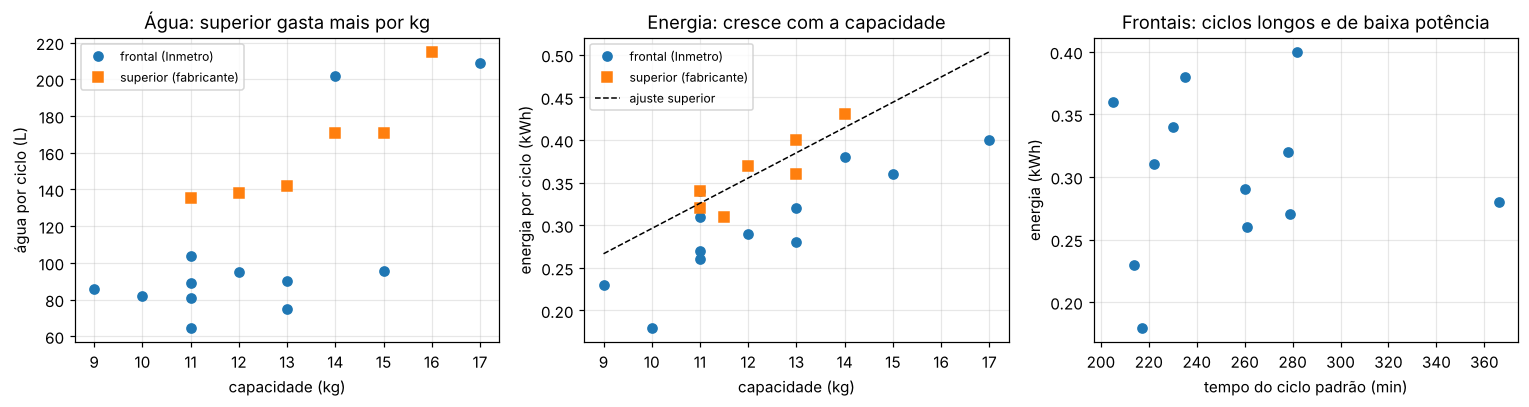

In [2]:
# ======================================================================
# DADOS REAIS (constantes de entrada). Fontes: ver "Fontes dos dados das máquinas" acima.
# ======================================================================
# Inmetro/PBE 2023, lava-e-seca frontal. Cada linha:
# (marca, modelo, capacidade_kg, energia_kwh_por_ciclo, agua_litros_por_ciclo, tempo_ciclo_min, eficiencia_lavagem)
DADOS_INMETRO_FRONTAL = [
    ("Brastemp",   "BNC10AB",     10.0, 0.179,  82.0, 217, 0.94),
    ("Samsung",    "WD90M4453MW",  9.0, 0.23,   86.0, 214, 0.92),
    ("Samsung",    "WD11M4453JW", 11.0, 0.31,   81.0, 222, 0.93),
    ("LG",         "CV3011BC4",   11.0, 0.27,   64.3, 279, 0.92),
    ("Midea",      "LSD11B1",     11.0, 0.26,   88.8, 261, 0.90),
    ("Electrolux", "LSP11",       11.0, 0.34,  104.0, 230, 0.88),
    ("Philco",     "PLS12B",      12.0, 0.29,   95.0, 260, 0.95),
    ("LG",         "CV5013BC4",   13.0, 0.32,   74.7, 278, 0.92),
    ("Midea",      "MF200D130WB", 13.0, 0.28,   89.9, 366, 0.94),
    ("LG",         "WD14EGS62",   14.0, 0.38,  202.0, 235, 0.94),
    ("Samsung",    "WD15H7300KP", 15.0, 0.36,   95.4, 205, 0.96),
    ("Samsung",    "WD17T6300GW", 17.0, 0.40,  208.8, 282, 0.91),
]
# Abertura superior, valores DECLARADOS por fabric(marca, modelo, capacidade_kg, energia_kwh_por_ciclo ou None, agua_litros_por_ciclo ou None)
DADOS_FABRICANTES_SUPERIOR = [
    ("Mueller",    "MLA11",       11.0, 0.32, None),
    ("Consul",     "CWH11AB",     11.0, 0.34, None),
    ("Brastemp",   "11 kg (ficha)", 11.0, None, 12.3*11.0),   # a ficha informa 12,3 L por kg
    ("Colormaq",   "LCA 11.5K",   11.5, 0.31, None),
    ("Brastemp",   "BWK12AB",     12.0, 0.37, 138.0),
    ("Brastemp",   "BWK13AB",     13.0, 0.36, 142.0),
    ("Electrolux", "LED13",       13.0, 0.40, None),
    ("Brastemp",   "BWK14AB",     14.0, 0.43, 171.0),
    ("Brastemp",   "BWF15AB",     15.0, None, 171.0),
    ("Brastemp",   "BWK16AB",     16.0, None, 215.0),
]
# Níveis de água (litros) de máquinas de abertura superior, do mais baixo ao mais alto: (capacidade_kg, [níveis])
NIVEIS_AGUA_SUPERIOR = {"Electrolux LED15 (15 kg)": (15.0, [70, 99, 124, 165, 206]),
                        "Electrolux LED17 (17 kg)": (17.0, [92, 112, 150, 192, 227]),
                        "Electrolux LED13 (13 kg), só extremos": (13.0, [67, 195])}

# Matriz numérica dos frontais: colunas = capacidade_kg, energia_kwh, agua_litros, tempo_min, eficiencia (fr)
dados_frontal = np.array([(r[2], r[3], r[4], r[5], r[6]) for r in DADOS_INMETRO_FRONTAL])
print("ABERTURA FRONTAL (Inmetro/PBE 2023)")
print(f"  {'modelo':<20}{'kg':>5}{'kWh/ciclo':>11}{'água (L)':>10}{'L/kg':>7}{'tempo (min)':>13}{'efic. lavagem':>15}")
for r in DADOS_INMETRO_FRONTAL:
    print(f"  {r[0]+' '+r[1]:<20}{r[2]:5.1f}{r[3]:11.3f}{r[4]:10.1f}{r[4]/r[2]:7.1f}{r[5]:13d}{r[6]:15.2f}")

# Ajuste da energia das superiores: mínimos quadrados passando pela origem, E = coeficiente × capacidade
energia_superior = np.array([(r[2], r[3]) for r in DADOS_FABRICANTES_SUPERIOR if r[3] is not None])
agua_superior    = np.array([(r[2], r[4]) for r in DADOS_FABRICANTES_SUPERIOR if r[4] is not None])
energia_kwh_por_kg_superior = float((energia_superior[:, 0] @ energia_superior[:, 1])/(energia_superior[:, 0] @ energia_superior[:, 0]))   # (kwh_por_kg_top)
agua_litros_por_kg_superior = float(np.mean(agua_superior[:, 1]/agua_superior[:, 0]))                                                      # (L_por_kg_top)
print("\nABERTURA SUPERIOR (declarado pelo fabricante)")
print(f"  energia: ajuste E ≈ {energia_kwh_por_kg_superior:.4f} kWh por kg de capacidade (11 kg -> {energia_kwh_por_kg_superior*11:.2f}; 13 kg -> {energia_kwh_por_kg_superior*13:.2f}; 16 kg -> {energia_kwh_por_kg_superior*16:.2f})")
print(f"  água no nível padrão: média de {agua_litros_por_kg_superior:.1f} L por kg de capacidade (intervalo {np.min(agua_superior[:,1]/agua_superior[:,0]):.1f} a {np.max(agua_superior[:,1]/agua_superior[:,0]):.1f})")

print("\nNíveis de água (L/kg de capacidade):")
niveis_por_kg = []
for nome, (capacidade_kg, niveis) in NIVEIS_AGUA_SUPERIOR.items():
    print(f"  {nome:<40}" + "  ".join(f"{n/capacidade_kg:5.1f}" for n in niveis))
    if len(niveis) == 5: niveis_por_kg.append(np.array(niveis)/capacidade_kg)
NIVEIS_AGUA_LITROS_POR_KG = np.mean(niveis_por_kg, axis=0)     # (NIVEIS_KG) nível médio dos dois modelos de 5 níveis
print(f"  nível médio dos dois modelos de 5 níveis: {np.round(NIVEIS_AGUA_LITROS_POR_KG, 1)} L/kg")

frontais_11kg = dados_frontal[dados_frontal[:, 0] == 11.0]                                         # (m11)
print(f"\nFrontais de 11 kg: água de {frontais_11kg[:,2].min():.0f} a {frontais_11kg[:,2].max():.0f} L ({frontais_11kg[:,2].min()/11:.1f} a {frontais_11kg[:,2].max()/11:.1f} L/kg), energia de {frontais_11kg[:,1].min():.2f} a {frontais_11kg[:,1].max():.2f} kWh, tempo de {frontais_11kg[:,3].min():.0f} a {frontais_11kg[:,3].max():.0f} min")
print(f"Eficiência de lavagem (Inmetro), média dos frontais: {dados_frontal[:,4].mean():.3f} (de {dados_frontal[:,4].min():.2f} a {dados_frontal[:,4].max():.2f})")

fig, eixos = plt.subplots(1, 3, figsize=(14, 3.8))
eixos[0].plot(dados_frontal[:, 0], dados_frontal[:, 2], "o", label="frontal (Inmetro)")
eixos[0].plot(agua_superior[:, 0], agua_superior[:, 1], "s", label="superior (fabricante)")
eixos[0].set(xlabel="capacidade (kg)", ylabel="água por ciclo (L)", title="Água: superior gasta mais por kg"); eixos[0].legend(fontsize=8)
eixos[1].plot(dados_frontal[:, 0], dados_frontal[:, 1], "o", label="frontal (Inmetro)")
eixos[1].plot(energia_superior[:, 0], energia_superior[:, 1], "s", label="superior (fabricante)")
capacidades_grafico = np.linspace(9, 17, 10); eixos[1].plot(capacidades_grafico, energia_kwh_por_kg_superior*capacidades_grafico, "k--", lw=1, label="ajuste superior")
eixos[1].set(xlabel="capacidade (kg)", ylabel="energia por ciclo (kWh)", title="Energia: cresce com a capacidade"); eixos[1].legend(fontsize=8)
eixos[2].plot(dados_frontal[:, 3], dados_frontal[:, 1], "o"); eixos[2].set(xlabel="tempo do ciclo padrão (min)", ylabel="energia (kWh)", title="Frontais: ciclos longos e de baixa potência")
plt.tight_layout(); plt.show()

**O que os dados dizem, e o que muda no modelo:**
- **A energia por ciclo é pequena e quase proporcional à capacidade:** de 0,18 a 0,46 kWh, ou cerca de R$ 0,2 a R$ 0,5 por ciclo. A **água domina o custo**.
- **Abertura superior pode gastar mais água por kg** do que a frontal (por volta de 12 L por kg contra 6 a 9 L por kg nas frontais de 9 a 13 kg). Por isso as duas famílias entram como **arquétipos diferentes**.
- **Os níveis de água são discretos** (5 níveis na maioria das superiores). O modelo, a princípio, escolhe $w$ continuamente.
- **As frontais têm ciclos de 3 a 6 horas e potência média baixa**, e não ciclos de 75 minutos. Então, no modelo, um arquétipo frontal tem **$P$ (potência média) muito menor** e tende a usar tempo, não água.
- **Faixa de água por kg das superiores:** de cerca de 5 a 15 L por kg conforme o nível. O modelo usa de 4,5 a 14 L por kg, o que **coincide com a faixa real**.
- **Tarifa de energia:** faturas residenciais da Light de março/2026 mostram de **R$ 1,12 a R$ 1,21 por kWh** com tributos, e o modelo usa R$ 1,14.

### Mas como comparar tantas máquinas? ###
Ao longo do problema, isso foi um fator. Comparar por cada fabricante pode ser precário, já que máquinas semelhantes em dados declarados podem apresentar funções e qualidades completamente diferentes.

A solução encontrada foi criar "grupos" que representassem as máquinas de dada faixa, de forma que posteriormente a pessoa pode escolher, dentro daquela faixa, qual máquina mais lhe interessa.

Os grupos consideram:

- **Potência média $P$:** faz o modelo reproduzir o **consumo de energia declarado** no ciclo de referência. Nas superiores, assumimos um ciclo padrão de 75 min (o mesmo tempo máximo da roupa normal). Nas frontais, usamos o tempo do Inmetro.
- **Faixa de água:** das superiores, de 4,5 a 14 L por kg (níveis reais). Da frontal, a faixa vista entre os modelos de 11 kg (5,8 a 9,9 L por kg).
- **Calibração da limpeza ($k_0$):** o ciclo padrão de uma máquina de referência a 80% da carga, com a água do nível padrão, deve atingir a **eficiência de lavagem média do Inmetro** (≈ 0,93). É a única âncora disponível para esse parâmetro.

### Fontes dos dados das máquinas

- **Inmetro / Programa Brasileiro de Etiquetagem (2023).** Tabela de lavadoras e secadoras automáticas de abertura frontal, edição de 19/06/2023: [PDF](https://www.gov.br/inmetro/pt-br/assuntos/avaliacao-da-conformidade/programa-brasileiro-de-etiquetagem/tabelas-de-eficiencia-energetica/lavadoras-de-roupa/lavadoras-e-secadoras-de-roupa-automaticas-com-abertura-frontal.pdf). Se o PDF não abrir, use a [página de tabelas de lavadoras do Inmetro](https://www.gov.br/inmetro/pt-br/assuntos/regulamentacao/avaliacao-da-conformidade/programa-brasileiro-de-etiquetagem/tabelas-de-eficiencia-energetica/lavadoras-de-roupa) ou o [sistema PBE](https://pbe.inmetro.gov.br/#/programas). Modelos usados: lista em `DADOS_INMETRO_FRONTAL`.
- **Abertura superior (valores declarados pelos fabricantes).**
  - Brastemp BWK13AB: [página oficial da Brastemp](https://www.brastemp.com.br/maquina-de-lavar-brastemp-13kg-branca-com-ciclo-tira-manchas-advanced-e-ciclo-antibolinha-bwk13ab-326125395/p) (0,36 kWh, 220 V). Água de 142 L (220 V): ficha oficial do modelo irmão [BWK13A9](https://www.brastemp.com.br/maquina-de-lavar-brastemp-13kg-cinza-platinum-com-ciclo-tira-manchas-advanced-e-ciclo-antibolinha-bwk13a9-326125397/p).
  - Brastemp BWK12AB: [Buscapé](https://www.buscape.com.br/lavadora-roupas/lavadora-brastemp-12kg-bwk12ab) (0,37 kWh). Água de 138 L: ficha do modelo irmão [BWK12A9 no Buscapé](https://www.buscape.com.br/lavadora-roupas/lavadora-brastemp-12kg-bwk12a9) (0,37 kWh e 138 L por ciclo).
  - Brastemp BWK14AB: [Zoom](https://www.zoom.com.br/lavadora-roupas/deumzoom/brastemp-14kg-bwk14ab-vale-a-pena) (0,43 kWh, 171 L e 4 níveis de água).
  - Electrolux LED13: [loja Electrolux](https://loja.electrolux.com.br/maquina-de-lavar-13kg-electrolux-essential-care-com-cesto-inox-jet-clean-e-ultra-filter--led13-/p) (0,4 kWh por ciclo, 150 L por ciclo e 5 níveis).
  - Mueller MLA11: [Buscapé](https://www.buscape.com.br/lavadora-roupas/lavadora-mueller-11kg-mla11). Colormaq LCA 11.5K: [Buscapé](https://www.buscape.com.br/lavadora-roupas/lavadora-colormaq-11-5kg-super-capacidade-lca-11-5k).
  - Níveis de água das Electrolux LED15 e LED17: [Casa dos Eletrodomésticos](https://www.casadoseletrodomesticos.com.br/maquina-de-lavar-gasta-quantos-litros-de-agua).
- **Faixas de consumo de energia por categoria (Inmetro, via Idec).** [Idec](https://idec.org.br/print/24463).
- **Tarifa de energia.** Faturas residenciais da Light de março/2026, com preço unitário de R$ 1,12 a R$ 1,21 por kWh com tributos.

**Aviso:** os valores de fabricantes foram lidos em páginas de fabricante e de comércio, não na tabela oficial dessa categoria. Confira o modelo exato no [sistema do Inmetro](https://pbe.inmetro.gov.br/#/programas) antes de citar um número específico.

### Tarifas no Rio de Janeiro (usados nesse trabalho)

- **Água (Águas do Rio, Região 1, Área A, residencial "Tarifa 2"):** R$ 7,44/m³ até 15 m³ e **R$ 16,36/m³ na faixa de 16 a 30 m³**, vigentes desde dezembro de 2025. Como a lavagem é consumo *Mínimo*, usamos a faixa 16–30 m³. A tabela publicada para **dezembro de 2026** é R$ 18,69/m³ nessa faixa (+14%).
- **Luz (Light, B1 residencial):** R$ 0,88/kWh homologado, sem impostos (reajuste de 15/03/2026). Com ICMS e PIS/COFINS, aproximadamente **R$ 1,14/kWh** (faturas de março de 2026 mostram ≈ R$ 1,13/kWh).
- **Bandeira tarifária:** **verde em novembro de 2026** (decisão da Aneel de 30/10/2026), sem cobrança adicional. Para comparação, o adicional por 100 kWh é de R$ 1,885 na amarela, R$ 4,463 na vermelha patamar 1 e R$ 7,877 na vermelha patamar 2.

### Classe para registrar preços ###
Útil para calcular a diferença em regiões com outros custos.

In [3]:
@dataclass(frozen=True)
class PrecosMercado:
    # Preços pagos pelo usuário. 
    # 'frozen=True' = o objeto é imutável.
    # Para testar outro preço (sensibilidade), cria-se uma CÓPIA com dataclasses.replace(...).
    agua_reais_por_litro: float        # R$ por litro de água
    energia_reais_por_kwh: float       # R$ por kWh, com impostos e bandeira tarifária

TARIFA_AGUA_REAIS_POR_M3 = 16.36       # Águas do Rio, Região 1, Área A, residencial "Tarifa 2", faixa de 16 a 30 m³ (dez/2025)
TARIFA_ENERGIA_COM_IMPOSTOS = 1.14     # R$/kWh, Light B1 com impostos
BANDEIRAS_REAIS_POR_100KWH = {"verde": 0.0, "amarela": 1.885, "vermelha 1": 4.463, "vermelha 2": 7.877}
BANDEIRA_VIGENTE = "verde"  #vigente em novembro/2026
adicional_bandeira_reais_por_kwh = BANDEIRAS_REAIS_POR_100KWH[BANDEIRA_VIGENTE]/100

PRECOS = PrecosMercado(
    agua_reais_por_litro = TARIFA_AGUA_REAIS_POR_M3/1000,
    energia_reais_por_kwh = TARIFA_ENERGIA_COM_IMPOSTOS + adicional_bandeira_reais_por_kwh,
)
print(f"Água: R$ {PRECOS.agua_reais_por_litro*1000:.2f}/m³  |  Luz: R$ {TARIFA_ENERGIA_COM_IMPOSTOS:.2f}/kWh + bandeira {BANDEIRA_VIGENTE} "
      f"(R$ {adicional_bandeira_reais_por_kwh:.4f}/kWh) = R$ {PRECOS.energia_reais_por_kwh:.2f}/kWh")

Água: R$ 16.36/m³  |  Luz: R$ 1.14/kWh + bandeira verde (R$ 0.0000/kWh) = R$ 1.14/kWh


## Dimensão 1 : A Máquina ##

### Objetivo e variáveis ###

**Objetivo**: Otimizar quanta roupa uma máquina lavará e quanto ela gastará.

**Método**: **KKT analítico**, com análise de casos e multiplicadores.
Posterior verificação numérica independente  com **SLSQP**, do `scipy`.


**Variáveis:**
- **água** $w$ (litros)
- **energia** = tempo × gasto médio: $E=P\,t/60$ (kWh), com $t$ a duração (min) e $P$ a potência média (kW)
- **carga** $m$ (kg de roupa por ciclo)

**Considerações:**
1. *O modo de lavagem da máquina depende da roupa.* Por exemplo, uma camisa sensível não pode ser lavada num ciclo pesado. A ausência dessa consideração destruiria as roupas do usuário. Cada **tipo de roupa** tem um tempo máximo de ciclo e um limite de carga, que entram como **restrições**, e o seu custo é medido.
2. *Marcas diferentes têm eficiências diferentes*, mas **não é objetivo fazer uma "disputa de marcas"**. O código gera **vários objetos "máquina"** (A, B, C, D), cada um com seus parâmetros, e traça-se o gráfico de funcionamento de cada um. **Os parâmetros vêm de dados reais**: cada objeto é um **grupo** construído a partir das máquinas vendidas no Brasil.

### Modelo do funcionamento da máquina ###

**Observação**: Na execução do trabalho diversas fórmulas têm elementos com nomes encurtados ou com símbolos os representando. No código, foi preferível utilizar variáveis com nomes identificáveis. Assim, há especificado na legenda o nome que cada variável assume nas fórmulas descritas.

In [4]:
@dataclass(frozen=True)
class PontoCalibracao:
    # Um ponto de funcionamento conhecido, usado para calibrar o coeficiente de limpeza.
    eficiencia_lavagem: float     # limpeza que a máquina deve atingir nesse ponto (média do Inmetro)
    capacidade_kg: float
    carga_kg: float
    agua_litros: float
    tempo_min: float

@dataclass(frozen=True)
class ModeloLimpeza:
    # Modelo de limpeza de um ciclo:  limpeza = 1 − exp(−Z),  Z = eficácia · k0 · t^a · (água/carga)^d · (1 − carga/capacidade)^θ
    expoente_tempo: float             # ('a')   rendimento decrescente do tempo (ASSUMIDO)
    expoente_agua_por_kg: float       # ('d')   rendimento decrescente da água por kg de roupa (ASSUMIDO)
    expoente_lotacao: float           # (theta, 'θ') quanto a máquina cheia piora a limpeza (ASSUMIDO)
    tempo_minimo_ciclo_min: float     # (T_MIN)     ciclo mais curto que a máquina faz
    coeficiente_base: float = 1.0     # (k0)        escala de limpeza; vem da calibração em dado real

    def calibrado_em(self, ponto: PontoCalibracao):
        # Devolve uma cópia cujo coeficiente_base faz o modelo dar exatamente 'ponto.eficiencia_lavagem' no ponto dado.
        fator = (ponto.tempo_min**self.expoente_tempo * ponto.agua_litros**self.expoente_agua_por_kg
                 * ponto.carga_kg**(-self.expoente_agua_por_kg) * (1 - ponto.carga_kg/ponto.capacidade_kg)**self.expoente_lotacao)
        return replace(self, coeficiente_base=-np.log(1 - ponto.eficiencia_lavagem)/fator)

@dataclass(frozen=True)
class TipoRoupa:
    # Exigências de um tipo de roupa: o que o ciclo precisa garantir e o que não pode ultrapassar.
    nome: str
    limpeza_minima: float             # (Cmin)   fração mínima de sujeira removida
    tempo_maximo_min: float           # (t_hi)   protege o tecido: ciclo não pode passar disso
    fracao_maxima_carga: float        # (frac)   fração máxima da capacidade da máquina que se pode carregar
    @property
    def z_minimo(self): return -np.log(1 - self.limpeza_minima)       # (Zmin) Z necessário para atingir a limpeza mínima

TIPOS_DE_ROUPA = {
    "resistente": TipoRoupa("resistente", 0.95, 120, 1.0),   # jeans, toalhas
    "normal":     TipoRoupa("normal",     0.90,  75, 1.0),   # camisetas, roupa do dia a dia
    "delicado":   TipoRoupa("delicado",   0.85,  30, 0.6),   # roupas finas: ciclo curto e carga reduzida
}

# Calibração: ciclo padrão de uma superior de 11 kg (carga de 80%, água do nível padrão, 75 min) deve dar a eficiência média do Inmetro
CICLO_PADRAO_SUPERIOR_MIN = 75.0         # (T_PADRAO_SUP) ASSUMIDO: duração do ciclo padrão das superiores
PONTO_CALIBRACAO = PontoCalibracao(
    eficiencia_lavagem = float(dados_frontal[:, 4].mean()),        # (EL_REF)
    capacidade_kg = 11.0, carga_kg = 0.8*11.0,
    agua_litros = agua_litros_por_kg_superior*11.0, tempo_min = CICLO_PADRAO_SUPERIOR_MIN)
MODELO_LIMPEZA = ModeloLimpeza(expoente_tempo=0.25, expoente_agua_por_kg=0.5, expoente_lotacao=0.05,
                               tempo_minimo_ciclo_min=15.0).calibrado_em(PONTO_CALIBRACAO)
print(f"coeficiente_base (k0) = {MODELO_LIMPEZA.coeficiente_base:.4f}   (calibrado para eficiência de lavagem de referência = {PONTO_CALIBRACAO.eficiencia_lavagem:.3f})")

coeficiente_base (k0) = 0.2478   (calibrado para eficiência de lavagem de referência = 0.926)


### Modelo do custo integrado ao da máquina ###

**Custo de um ciclo**:
$$ f = c_w\,w + c_t\,t,\qquad c_w=a_w,\quad c_t=\frac{a_e\,P}{60} $$
Onde $f$ é o custo do ciclo (R$), $w$ a água (L), $t$ o tempo (min), $c_w$ o custo da água (R$/L), $c_t$ o custo do tempo (R$/min), $a_w$ o preço da água (R$/L), $a_e$ o preço da energia (R$/kWh) e $P$ a potência média (kW).

**Custo por kg** (o que queremos minimizar na escolha da carga): $\;\varphi = f/m$, onde $\varphi$ é o custo por kg (R$/kg) e $m$ a carga (kg).

**Limpeza (modelo assumido).** $C=1-e^{-Z}$, com
$$ Z=\varepsilon\,k_0\; t^{a}\,\Big(\frac{w}{m}\Big)^{d}\Big(1-\frac mM\Big)^{\theta} $$
Onde $C$ é a limpeza (0 a 1), $Z$ o índice de limpeza, $\varepsilon$ a eficácia relativa da máquina, $k_0$ a escala do modelo (calibrada no Inmetro), $M$ a capacidade da máquina (kg) e $a$, $d$, $\theta$ os expoentes do tempo, da água por kg e da lotação.
- $t^a$ e $(w/m)^d$: mais tempo e **mais água por kg** limpam mais, com retornos decrescentes ($a,d<1$).
- $(1-m/M)^\theta$: máquina quase cheia lava pior (a roupa não se move).

**Restrições:**
- limpeza mínima do tipo de roupa: $\;g_1=\ln Z_{min}-\ln(\varepsilon k_0)-a\ln t-d\ln w+d\ln m-\theta\ln(1-m/M)\le0,\;\; Z_{min}=-\ln(1-C_{min})$
  - Onde $g_1$ é a folga da limpeza ($g_1\le0$: limpeza mínima atingida), $C_{min}$ a limpeza mínima do tipo de roupa e $Z_{min}$ o índice de limpeza correspondente.
- **proteção do tecido:** $t\le t_{max}(\text{tipo})$ e $m\le f_{max}(\text{tipo})\,M$
  - Onde $t_{max}$ é o tempo máximo do tipo de roupa (min) e $f_{max}$ a fração máxima da capacidade que se pode carregar.
- **limites físicos da máquina:** $t\ge t_{min}$, $w_{lo}\le w\le w_{hi}$ (nível mínimo e máximo de água)
  - Onde $t_{min}$ é o tempo mínimo do ciclo (min) e $w_{lo}$, $w_{hi}$ são a água mínima e máxima (L).

O **nível mínimo de água** e o **tempo mínimo** fazem com que lavar pouca roupa custe quase o mesmo que lavar bastante. **É o custo fixo de ligar a máquina**.

### Método 1 — KKT analítico

Em duas etapas: (a) para uma carga $m$ fixa, achar o tempo $t$ e a água $w$ de menor custo; (b) escolher a carga.

**(a) Para carga $m$ fixa**, o problema é minimizar $c_t t + c_w w$ sujeito à limpeza mínima e às caixas.

*Passo 1: restrição em log.* Com $Z=\varepsilon k_0\,t^{a}(w/m)^{d}(1-m/M)^{\theta}\ge Z_{min}$, tomando o logaritmo e passando para o lado direito o que depende de $m$:

$$a\ln t+d\ln w\ \ge\ \ln K(m),\qquad \ln K(m)=\ln\frac{Z_{min}}{\varepsilon k_0}+d\ln m-\theta\ln(1-m/M)$$
Onde $K(m)$ é o valor que $t^{a}w^{d}$ precisa atingir para limpar a carga $m$.

Nas variáveis $(\ln t,\ln w)$ o custo é convexo e a restrição é linear, então o KKT é **suficiente**: o ponto que o satisfaz é o mínimo global.

*Passo 2: Lagrangiano.* Escreve-se a limpeza mínima como $Z_{min}-Z\le0$ e o limite de tempo como $t-t_{max}\le0$:

$$\mathcal{L}=c_t t+c_w w+\lambda_1\,(Z_{min}-Z)+\lambda_2\,(t-t_{max})$$
Onde $\mathcal{L}$ é o Lagrangiano, $\lambda_1\ge0$ o multiplicador da limpeza mínima e $\lambda_2\ge0$ o do limite de tempo (R$ por minuto). No caso interior (nenhum limite ativo), $\lambda_2=0$.

Como $Z$ é um produto de potências, $\partial Z/\partial t=aZ/t$ e $\partial Z/\partial w=dZ/w$. Com a limpeza ativa ($Z=Z_{min}$), define-se $\Lambda=\lambda_1 Z_{min}$: é o multiplicador da limpeza na escala logarítmica (equivale a usar a restrição $a\ln t+d\ln w\ge\ln K$ com multiplicador $\Lambda$). No código, `lam` é $\Lambda$.

*Passo 3: estacionariedade.* $\partial\mathcal{L}/\partial t=c_t-\Lambda a/t+\lambda_2=0$ e $\partial\mathcal{L}/\partial w=c_w-\Lambda d/w=0$. No caso interior ($\lambda_2=0$):

$$t=\frac{\Lambda a}{c_t},\qquad w=\frac{\Lambda d}{c_w}$$

*Passo 4: custo no ótimo (caso interior).* $c_t t=\Lambda a$ e $c_w w=\Lambda d$, então:

$$f^*(m)=c_t t+c_w w=\Lambda\,(a+d)$$
Onde $f^*(m)$ é o custo mínimo de um ciclo com carga $m$. Com o tempo no limite, $w=\Lambda d/c_w$ continua valendo, mas $f^*=c_t t_{max}+c_w w$, e $\Lambda(a+d)$ deixa de ser o custo.

*Passo 5: valor de $\Lambda$.* Com a restrição ativa, $a\ln t+d\ln w=\ln K$. Substituindo $t$ e $w$:

$$a\ln\frac{\Lambda a}{c_t}+d\ln\frac{\Lambda d}{c_w}=\ln K\ \Rightarrow\ (a+d)\ln\Lambda+a\ln\frac{a}{c_t}+d\ln\frac{d}{c_w}=\ln K$$

$$\Lambda=\exp\!\Big[\tfrac{\ln K(m)-a\ln(a/c_t)-d\ln(d/c_w)}{a+d}\Big]$$

*Caixas.* Se esse ponto viola uma **caixa** (tempo máximo do tecido, água mínima...), ela fica ativa e o outro insumo sai da própria restrição. O código testa **todos os casos** (interior, $t$ no limite, $w$ no limite, cantos) e fica com o de menor custo entre os viáveis.

**(b) Escolha da carga (caso interior).** Minimiza-se o custo por kg, $\varphi(m)=f^*(m)/m$.

*Passo 6: como $\Lambda$ depende de $m$.* Só $\ln K(m)$ depende de $m$:

$$\ln\Lambda=\frac{d\ln m-\theta\ln(1-m/M)}{a+d}+\text{const}$$

*Passo 7: log do custo por kg.* Como $f^*=\Lambda(a+d)$, $\ln f^*=\ln\Lambda+\ln(a+d)$, e $\ln(a+d)$ não depende de $m$:

$$\ln\varphi=\ln f^*-\ln m=\ln\Lambda-\ln m+\text{const}=-\frac{a}{a+d}\ln m-\frac{\theta}{a+d}\ln\!\Big(1-\frac mM\Big)+\text{const}$$

(usando $\frac{d}{a+d}-1=-\frac{a}{a+d}$), ou seja, $\varphi\propto m^{-a/(a+d)}(1-m/M)^{-\theta/(a+d)}$.

*Passo 8: derivada igual a zero.* Como $\frac{d}{dm}\ln(1-m/M)=-\frac{1}{M-m}$:

$$\frac{d\ln\varphi}{dm}=-\frac{a}{(a+d)\,m}+\frac{\theta}{(a+d)(M-m)}=0\ \Rightarrow\ a(M-m)=\theta m$$

$$ \boxed{\,m^*=\frac{a}{a+\theta}\,M\,} $$
Onde $m^*$ é a carga ótima (kg).

*Passo 9: é mínimo.* Quando $m\to0$ ou $m\to M$, $\ln\varphi\to+\infty$ (pelos termos em $\ln m$ e $\ln(1-m/M)$). Com um único ponto crítico entre os dois extremos, ele é o mínimo: o fundo do "U" da curva de custo por kg.

Fórmula fechada: a carga ótima é uma **fração fixa da capacidade**, independente dos preços e do expoente $d$ (que cancela no passo 7). Com $a=0{,}25$ e $\theta=0{,}05$, dá $0{,}25/0{,}30\approx$ **83,3%** (9,17 kg numa máquina de 11 kg).

**Limite da fórmula.** Ela vale só quando nenhuma caixa está ativa. No caso real, o limite de tempo do tecido está ativo e o ótimo numérico cai para ≈ 72% (7,9 kg, 75 min, 89 L); a fórmula serve como referência.

In [5]:
### Classe Maquina, Ciclos de lavagem, Carga Ótima ###
@dataclass(frozen=True)
class CicloLavagem:
    # Resultado de escolher tempo e água para uma carga fixa.
    custo_reais: float
    tempo_min: float
    agua_litros: float
    caso: str                         # qual restrição ficou ativa (para a análise de casos do KKT)

@dataclass(frozen=True)
class CargaOtima:
    # Resultado de escolher também a carga (o que minimiza o custo por kg).
    carga_kg: float
    ciclo: CicloLavagem
    energia_kwh: float
    custo_por_kg: float               # (phi)

@dataclass(frozen=True)
class Maquina:
    nome: str
    capacidade_kg: float              # (M)    carga máxima
    potencia_media_kw: float          # (P)    potência elétrica média durante o ciclo
    eficacia_relativa: float          # (eps)  1,0 = máquina de referência
    agua_min_litros_por_kg: float     # (w_lo_kg) menor nível de água, por kg de capacidade
    agua_max_litros_por_kg: float     # (w_hi_kg) maior nível de água
    fonte: str = ""
    precos: PrecosMercado = PRECOS            # preços usados nas contas desta máquina
    modelo: ModeloLimpeza = MODELO_LIMPEZA    # modelo de limpeza desta máquina

    # ---- grandezas derivadas ----
    @property
    def coeficiente_limpeza(self): return self.modelo.coeficiente_base*self.eficacia_relativa      # (k)
    @property
    def agua_minima_litros(self): return self.agua_min_litros_por_kg*self.capacidade_kg            # (w_lo)
    @property
    def agua_maxima_litros(self): return self.agua_max_litros_por_kg*self.capacidade_kg            # (w_hi)
    @property
    def custo_energia_reais_por_minuto(self):                                                      # (ct)
        return self.precos.energia_reais_por_kwh*self.potencia_media_kw/60

    # ---- contas de UM ciclo ----
    def custo_do_ciclo(self, tempo_min, agua_litros):
        # custo = preço da energia × potência × tempo + preço da água × litros
        return self.custo_energia_reais_por_minuto*tempo_min + self.precos.agua_reais_por_litro*agua_litros

    def energia_do_ciclo_kwh(self, tempo_min): return self.potencia_media_kw*tempo_min/60

    def limpeza_do_ciclo(self, carga_kg, tempo_min, agua_litros):
        # fração de sujeira removida: 1 − exp(−Z)
        m = self.modelo
        z = (self.coeficiente_limpeza * tempo_min**m.expoente_tempo * (agua_litros/carga_kg)**m.expoente_agua_por_kg
             * (1 - carga_kg/self.capacidade_kg)**m.expoente_lotacao)
        return 1 - np.exp(-z)

    # ---- Método 1 da Dimensão 1: KKT com análise de casos ----
    def ciclo_para_carga(self, tipo: TipoRoupa, carga_kg, tempo_maximo_min=None) -> Optional[CicloLavagem]:
        # (ciclo_fixo) Para uma carga fixa, escolhe tempo e água de menor custo que atingem a limpeza mínima.
        # Testa todos os casos de restrição ativa e fica com o mais barato entre os viáveis. Devolve None se for inviável.
        m = self.modelo
        t_max = tipo.tempo_maximo_min if tempo_maximo_min is None else tempo_maximo_min
        if carga_kg > tipo.fracao_maxima_carga*self.capacidade_kg + 1e-9: return None
        c_tempo = self.custo_energia_reais_por_minuto; c_agua = self.precos.agua_reais_por_litro
        ln_K = (np.log(tipo.z_minimo/self.coeficiente_limpeza) + m.expoente_agua_por_kg*np.log(carga_kg)
                - m.expoente_lotacao*np.log(max(1 - carga_kg/self.capacidade_kg, 1e-300)))      # ln K(m): exigência de limpeza para essa carga
        candidatos = []
        def tentar(tempo, agua, caso):
            # só aceita pontos que respeitam as caixas (tempo, água) e a limpeza mínima
            if (m.tempo_minimo_ciclo_min - 1e-9 <= tempo <= t_max + 1e-9
                    and self.agua_minima_litros - 1e-9 <= agua <= self.agua_maxima_litros + 1e-9
                    and m.expoente_tempo*np.log(tempo) + m.expoente_agua_por_kg*np.log(agua) >= ln_K - 1e-9):
                candidatos.append(CicloLavagem(c_tempo*tempo + c_agua*agua, tempo, agua, caso))
        a, d_exp = m.expoente_tempo, m.expoente_agua_por_kg
        lam = np.exp((ln_K - a*np.log(a/c_tempo) - d_exp*np.log(d_exp/c_agua))/(a + d_exp))       # multiplicador Λ da limpeza (caso interior)
        tentar(lam*a/c_tempo, lam*d_exp/c_agua, "interior (limpeza ativa)")
        for t_borda in (m.tempo_minimo_ciclo_min, t_max):
            tentar(t_borda, np.exp((ln_K - a*np.log(t_borda))/d_exp), "tempo no limite")
        for w_borda in (self.agua_minima_litros, self.agua_maxima_litros):
            tentar(np.exp((ln_K - d_exp*np.log(w_borda))/a), w_borda, "água no limite")
        for t_borda in (m.tempo_minimo_ciclo_min, t_max):
            for w_borda in (self.agua_minima_litros, self.agua_maxima_litros):
                tentar(t_borda, w_borda, "limpeza folgada (custo fixo)")
        return min(candidatos, key=lambda x: (x.custo_reais, x.tempo_min, x.agua_litros, x.caso)) if candidatos else None

    def carga_otima(self, tipo: TipoRoupa, tempo_maximo_min=None) -> CargaOtima:
        # (otimo_carga) Escolhe a carga que minimiza o custo por kg: grade grossa + refinamento em 1 dimensão.
        def custo_por_kg(carga):
            ciclo = self.ciclo_para_carga(tipo, carga, tempo_maximo_min)
            return ciclo.custo_reais/carga if ciclo else np.inf
        cargas = np.linspace(0.05*self.capacidade_kg, tipo.fracao_maxima_carga*self.capacidade_kg*0.999, 400)
        valores = np.array([custo_por_kg(c) for c in cargas]); i = int(np.argmin(valores))
        refino = minimize_scalar(custo_por_kg, bounds=(cargas[max(i - 1, 0)], cargas[min(i + 1, len(cargas) - 1)]),
                                 method="bounded", options={"xatol": 1e-9})
        ciclo = self.ciclo_para_carga(tipo, refino.x, tempo_maximo_min)
        return CargaOtima(refino.x, ciclo, self.energia_do_ciclo_kwh(ciclo.tempo_min), ciclo.custo_reais/refino.x)

    def carga_otima_formula_fechada_kg(self):
        # (m_cf) m* = a/(a+θ)·capacidade. Vale só quando NENHUM limite está ativo; serve de teto de referência.
        return self.modelo.expoente_tempo/(self.modelo.expoente_tempo + self.modelo.expoente_lotacao)*self.capacidade_kg

    def multiplicador_tempo(self, tipo: TipoRoupa):
        # (mu_t = λ₂) Preço-sombra do tempo máximo: R$ por minuto de limite a mais; usa Λ = c_w·w/d.
        # Devolve (previsto pelo KKT, conferência relaxando o limite em 1 min).
        otimo = self.carga_otima(tipo)
        lam_agua = self.precos.agua_reais_por_litro*otimo.ciclo.agua_litros/self.modelo.expoente_agua_por_kg
        previsto = lam_agua*self.modelo.expoente_tempo/otimo.ciclo.tempo_min - self.custo_energia_reais_por_minuto
        custo_base = self.ciclo_para_carga(tipo, otimo.carga_kg).custo_reais
        custo_relaxado = self.ciclo_para_carga(tipo, otimo.carga_kg, tempo_maximo_min=tipo.tempo_maximo_min + 1).custo_reais
        return previsto, custo_base - custo_relaxado

    # ---- saídas para as próximas dimensões e para gráficos ----
    def tabela_custo_por_pecas(self, tipo: TipoRoupa, pecas_por_kg):
        # (tabela_custo) custo de lavar u peças, u = 0..capacidade em peças. É a ENTRADA da Dimensão 2.
        capacidade_pecas = int(tipo.fracao_maxima_carga*self.capacidade_kg*pecas_por_kg + 1e-9)
        custo_por_pecas = np.zeros(capacidade_pecas + 1)
        for u in range(1, capacidade_pecas + 1):
            ciclo = self.ciclo_para_carga(tipo, u/pecas_por_kg)
            custo_por_pecas[u] = ciclo.custo_reais if ciclo else np.inf     # inf = ciclo inviável
        return custo_por_pecas

    def curva_custo_por_kg(self, tipo: TipoRoupa, cargas_kg):
        return np.array([(self.ciclo_para_carga(tipo, c).custo_reais/c if self.ciclo_para_carga(tipo, c) else np.nan) for c in cargas_kg])

    # ---- variante com níveis de água discretos (como nas máquinas reais) ----
    def ciclo_com_niveis_discretos(self, tipo: TipoRoupa, carga_kg, niveis_litros_por_kg=None):
        # (ciclo_discreto) a máquina só aceita os níveis de água listados; para cada nível, usa o menor tempo viável.
        niveis_litros_por_kg = NIVEIS_AGUA_LITROS_POR_KG if niveis_litros_por_kg is None else niveis_litros_por_kg
        m = self.modelo
        if carga_kg > tipo.fracao_maxima_carga*self.capacidade_kg + 1e-9: return None
        ln_K = (np.log(tipo.z_minimo/self.coeficiente_limpeza) + m.expoente_agua_por_kg*np.log(carga_kg)
                - m.expoente_lotacao*np.log(1 - carga_kg/self.capacidade_kg))
        melhor = None
        for nivel in niveis_litros_por_kg:
            agua = nivel*self.capacidade_kg
            tempo = max(m.tempo_minimo_ciclo_min, np.exp((ln_K - m.expoente_agua_por_kg*np.log(agua))/m.expoente_tempo))
            if tempo <= tipo.tempo_maximo_min + 1e-9:
                custo = self.custo_do_ciclo(tempo, agua)
                if melhor is None or custo < melhor.custo_reais: melhor = CicloLavagem(custo, tempo, agua, "nível discreto")
        return melhor

    def carga_otima_discreta(self, tipo: TipoRoupa):
        cargas = np.linspace(0.05*self.capacidade_kg, tipo.fracao_maxima_carga*self.capacidade_kg*0.999, 600)
        valores = [(self.ciclo_com_niveis_discretos(tipo, c).custo_reais/c if self.ciclo_com_niveis_discretos(tipo, c) else np.inf) for c in cargas]
        i = int(np.argmin(valores)); ciclo = self.ciclo_com_niveis_discretos(tipo, cargas[i])
        return CargaOtima(cargas[i], ciclo, self.energia_do_ciclo_kwh(ciclo.tempo_min), valores[i])


# ======================================================================
# CLASSE ConfirmacaoNumerica: resolve o problema COMPLETO em carga, tempo e água com um otimizador numérico
# (Confere o resultado do KKT)
# ======================================================================
class ConfirmacaoNumerica:
    # Trabalha em variáveis logarítmicas y = (ln carga, ln tempo, ln água)
    def __init__(self, maquina: Maquina, tipo: TipoRoupa):
        self.maquina, self.tipo = maquina, tipo
        self.limite_inferior = np.log([0.05*maquina.capacidade_kg, maquina.modelo.tempo_minimo_ciclo_min, maquina.agua_minima_litros])   # (lo)
        self.limite_superior = np.log([tipo.fracao_maxima_carga*maquina.capacidade_kg*0.999, tipo.tempo_maximo_min, maquina.agua_maxima_litros])  # (hi)

    def custo_por_kg(self, y):                                     # (phi_y) função objetivo
        carga, tempo, agua = np.exp(y)
        return (self.maquina.custo_energia_reais_por_minuto*tempo + self.maquina.precos.agua_reais_por_litro*agua)/carga

    def violacao_limpeza(self, y):                                 # (g1_y) positivo = limpeza insuficiente
        m = self.maquina.modelo; carga = np.exp(y[0])
        return (np.log(self.tipo.z_minimo) - np.log(self.maquina.coeficiente_limpeza) - m.expoente_tempo*y[1]
                - m.expoente_agua_por_kg*y[2] + m.expoente_agua_por_kg*y[0] - m.expoente_lotacao*np.log(1 - carga/self.maquina.capacidade_kg))

    def resolver_por_slsqp(self):
        # SLSQP do scipy com a restrição de limpeza. Devolve ((carga, tempo, água), custo por kg).
        restricoes = [{"type": "ineq", "fun": lambda y: -self.violacao_limpeza(y)}]
        r = minimize(self.custo_por_kg, np.log([0.5*self.maquina.capacidade_kg, 60.0, 80.0]), method="SLSQP",
                     bounds=list(zip(self.limite_inferior, self.limite_superior)), constraints=restricoes, options={"ftol": 1e-13, "maxiter": 500})
        return np.exp(r.x), r.fun


# ======================================================================
# OBJETOS: as quatro máquinas (grupos derivados dos dados reais)
# ======================================================================
def potencia_pela_etiqueta(energia_kwh, duracao_min):
    # (P_de_etiqueta) potência média que reproduz a energia declarada na etiqueta para a duração do ciclo padrão
    return energia_kwh/(duracao_min/60)

def maquina_superior(nome, capacidade_kg):
    # (arq_superior) abertura superior: energia = ajuste dos fabricantes; ciclo padrão assumido de 75 min
    return Maquina(nome, capacidade_kg, potencia_pela_etiqueta(energia_kwh_por_kg_superior*capacidade_kg, CICLO_PADRAO_SUPERIOR_MIN),
                   1.0, 4.5, 14.0, "superior: energia = ajuste dos fabricantes")

tempo_ciclo_frontal_11kg_min = float(np.mean([r[5] for r in DADOS_INMETRO_FRONTAL if r[2] == 11.0]))   # (t_front)
energia_frontal_11kg_kwh     = float(np.mean([r[3] for r in DADOS_INMETRO_FRONTAL if r[2] == 11.0]))   # (e_front)
agua_frontal_11kg_por_kg     = [r[4]/11.0 for r in DADOS_INMETRO_FRONTAL if r[2] == 11.0]               # (w_front)

MAQUINAS = [
    Maquina("A (frontal 11 kg)", 11.0, potencia_pela_etiqueta(energia_frontal_11kg_kwh, tempo_ciclo_frontal_11kg_min), 1.0,
            min(agua_frontal_11kg_por_kg), max(agua_frontal_11kg_por_kg), "frontal: média dos modelos de 11 kg do Inmetro"),
    maquina_superior("B (superior 11 kg)", 11.0),
    maquina_superior("C (superior 13 kg)", 13.0),
    maquina_superior("D (superior 16 kg)", 16.0),
]
MAQUINA_REFERENCIA = MAQUINAS[1]       # (B) superior de 11 kg, a mais comum; usada nas Dimensões 2 e 3
for mq in MAQUINAS:
    print(f"  {mq.nome:<20} capacidade={mq.capacidade_kg:4.1f} kg  potência={mq.potencia_media_kw:.3f} kW  água {mq.agua_minima_litros:.0f}-{mq.agua_maxima_litros:.0f} L ({mq.agua_min_litros_por_kg:.1f}-{mq.agua_max_litros_por_kg:.1f} L/kg)")

  A (frontal 11 kg)    capacidade=11.0 kg  potência=0.071 kW  água 64-104 L (5.8-9.5 L/kg)
  B (superior 11 kg)   capacidade=11.0 kg  potência=0.261 kW  água 50-154 L (4.5-14.0 L/kg)
  C (superior 13 kg)   capacidade=13.0 kg  potência=0.308 kW  água 58-182 L (4.5-14.0 L/kg)
  D (superior 16 kg)   capacidade=16.0 kg  potência=0.379 kW  água 72-224 L (4.5-14.0 L/kg)


### Resultado do ciclo ótimo ###

In [6]:
# ---------- Resultado do Método 1 (KKT) para a máquina de referência, três tipos de roupa ----------
print(f"Máquina {MAQUINA_REFERENCIA.nome}")
print(f"{'roupa':<11}{'carga (kg)':>11}{'t (min)':>9}{'w (L)':>8}{'kWh':>7}{'R$/ciclo':>10}{'R$/kg':>8}  caso")
otimos_por_tipo = {}
for nome_tipo, tipo in TIPOS_DE_ROUPA.items():
    o = MAQUINA_REFERENCIA.carga_otima(tipo); otimos_por_tipo[nome_tipo] = o
    print(f"{nome_tipo:<11}{o.carga_kg:11.2f}{o.ciclo.tempo_min:9.1f}{o.ciclo.agua_litros:8.1f}{o.energia_kwh:7.2f}{o.ciclo.custo_reais:10.2f}{o.custo_por_kg:8.3f}  {o.ciclo.caso}")
print(f"\nFórmula fechada m* = a/(a+θ)·M = {MAQUINA_REFERENCIA.carga_otima_formula_fechada_kg():.3f} kg   |   numérico (roupa normal) = {otimos_por_tipo['normal'].carga_kg:.3f} kg")

Máquina B (superior 11 kg)
roupa       carga (kg)  t (min)   w (L)    kWh  R$/ciclo   R$/kg  caso
resistente        8.18    120.0   125.1   0.52      2.64   0.323  tempo no limite
normal            7.89     75.0    89.3   0.33      1.83   0.232  tempo no limite
delicado          6.15     30.0    71.5   0.13      1.32   0.214  tempo no limite

Fórmula fechada m* = a/(a+θ)·M = 9.167 kg   |   numérico (roupa normal) = 7.894 kg


### Resultado encontrado ###

- **Com os parâmetros ancorados em dados reais, o tempo máximo fica ativo nos três tipos de roupa** (coluna "caso" acima). O motivo é que a energia é relativamente **barata** (potência média de cerca de 0,26 kW, ou R$ 0,005 por minuto) e a água é mais **cara** (R$ 0,016 por litro), então o modelo prefere limpeza pelo **tempo** até atingir no limite do tipo de roupa.
- **Consequência para a fórmula fechada:** a carga ótima $m^*=\frac{a}{a+\theta}M\approx 83\%\,M$ vale só no caso **interior** (nenhum limite ativo). Com o tempo no limite, a carga ótima numérica fica **abaixo** dela (≈ 72% da capacidade na roupa normal).
- **Roupa delicada:** além do tempo, a carga é limitada a 60% da máquina. O tempo máximo de 30 min leva a máquina a compensar com mais água por kg.

### Preço de proteger o tecido (multiplicador da restrição de tempo) ###

Com $t$ no limite superior, a estacionariedade em $t$ dá $\lambda_2=\Lambda\,a/t-c_t\ge0$, com $\Lambda=c_w w/d$ vindo da estacionariedade em $w$. Onde $\lambda_2$ é o multiplicador da restrição $t\le t_{max}$ (R$ por minuto) e $\Lambda$ o multiplicador da limpeza (o `mu_t` do código é $\lambda_2$). Ele mede **quanto custaria (em R$ por ciclo) cada minuto a menos de ciclo permitido**, isto é, o **preço da proteção**.

In [7]:
# ---------- Preço-sombra do tempo máximo, para cada tipo de roupa ----------
print(f"{'roupa':<11}{'λ₂ previsto pelo KKT (R$/min)':>32}{'economia ao relaxar 1 min (R$)':>34}")
for nome_tipo, tipo in TIPOS_DE_ROUPA.items():
    previsto, conferido = MAQUINA_REFERENCIA.multiplicador_tempo(tipo)
    print(f"{nome_tipo:<11}{previsto:32.4f}{conferido:34.4f}")

roupa         λ₂ previsto pelo KKT (R$/min)    economia ao relaxar 1 min (R$)
resistente                           0.0036                            0.0035
normal                               0.0048                            0.0047
delicado                             0.0145                            0.0141


### Confirmação numérica (SLSQP) ###

In [8]:
tipo_normal = TIPOS_DE_ROUPA["normal"]
(carga_sl, tempo_sl, agua_sl), custo_sl = ConfirmacaoNumerica(MAQUINA_REFERENCIA, tipo_normal).resolver_por_slsqp()
kkt = MAQUINA_REFERENCIA.carga_otima(tipo_normal)
print(f"{'método':<26}{'carga (kg)':>11}{'t (min)':>9}{'w (L)':>8}{'R$/kg':>9}")
print(f"{'KKT (casos + 1D)':<26}{kkt.carga_kg:11.3f}{kkt.ciclo.tempo_min:9.2f}{kkt.ciclo.agua_litros:8.2f}{kkt.custo_por_kg:9.4f}")
print(f"{'SLSQP (scipy)':<26}{carga_sl:11.3f}{tempo_sl:9.2f}{agua_sl:8.2f}{custo_sl:9.4f}")

método                     carga (kg)  t (min)   w (L)    R$/kg
KKT (casos + 1D)                7.894    75.00   89.34   0.2322
SLSQP (scipy)                   7.894    75.00   89.34   0.2322


Resultados coincidem.

### Números das fórmulas ###

In [9]:
mod = MODELO_LIMPEZA; mq = MAQUINA_REFERENCIA; tipo = TIPOS_DE_ROUPA["normal"]; o = mq.carga_otima(tipo)
print(f"expoentes (assumidos):  a = {mod.expoente_tempo}   d = {mod.expoente_agua_por_kg}   θ = {mod.expoente_lotacao}")
print(f"k0 = {mod.coeficiente_base:.4f}   (calibrado para a eficiência de referência {PONTO_CALIBRACAO.eficiencia_lavagem:.3f})")
mu_t, _ = mq.multiplicador_tempo(tipo)                       # preço-sombra do limite de tempo (λ₂ = mu_t)
a_, d_ = mod.expoente_tempo, mod.expoente_agua_por_kg
mu_formula = a_*mq.precos.agua_reais_por_litro*o.ciclo.agua_litros/(d_*tipo.tempo_maximo_min) - mq.custo_energia_reais_por_minuto
print(f"preço-sombra do tempo (código) = {mu_t:.4f} R$/min   |   pela fórmula λ₂ = Λ·a/t_máx − c_t, com Λ = c_w·w/d = {mu_formula:.4f} R$/min")

expoentes (assumidos):  a = 0.25   d = 0.5   θ = 0.05
k0 = 0.2478   (calibrado para a eficiência de referência 0.926)
preço-sombra do tempo (código) = 0.0048 R$/min   |   pela fórmula λ₂ = Λ·a/t_máx − c_t, com Λ = c_w·w/d = 0.0048 R$/min


## Dimensão 2 : O Indivíduo ##

Um indivíduo tem uma quantidade de roupas, usa $v$ peças por dia e precisa decidir **quando** lavar.

### Modelo da disponibilidade ###

Fatores considerados:

- **quanto ele quer economizar**: o peso $p$ (R$ por dia, por unidade de insatisfação. Uma unidade de custo, na prática);
- **quantas roupas ele tem disponíveis**: $N$ peças da classe;
- **o grau de satisfação dele em razão da quantidade de roupas disponíveis**.

**Métodos:** **Programação Dinâmica** (que resolve o problema), comparada com **regras simples** ("lave quando acumular $n$ dias") que as pessoas usam na prática.

**Quantidade disponível.** Para uma classe de roupa, o que importa é $q$, o número de peças **limpas** à mão:
$$ q=\text{quantidade}-\text{consumidas},\qquad \text{consumidas}=v_{consumo}\cdot t_{dias} $$
Onde $q$ é o número de peças limpas, $v_{consumo}$ as peças usadas por dia (**depende do tipo de roupa**) e $t_{dias}$ o número de dias (distinto do tempo de ciclo $t$, em minutos, da Dimensão 1).

A roupa existe em três situações: **suja** ($x_1$), **secando** ($x_2$, lavada no dia anterior) e **limpa** ($x_3=q$).
Cada dia o usuário veste $v$ peças limpas e lava $u$ peças sujas, que levam um dia para secar:
$$ x_1^{+}=x_1-u+\min(v,x_3),\qquad x_2^{+}=u,\qquad x_3^{+}=x_3-\min(v,x_3)+x_2,\qquad x_1+x_2+x_3=N $$
Onde $x_1$, $x_2$, $x_3$ são as peças sujas, secando e limpas, o sobrescrito $+$ indica o dia seguinte, $v$ são as peças vestidas por dia, $u$ as peças lavadas no dia e $N$ o total de peças.

**Satisfação.** É um **polinômio** da disponibilidade relativa. Com $F_{ref}=v\,T_{ref}$ o estoque que deixa o usuário plenamente satisfeito (autonomia de $T_{ref}$ dias):
$$ \rho=\min\!\Big(1,\frac{q}{F_{ref}}\Big),\qquad g(\rho)=(1+\kappa)\,\rho-\kappa\,\rho^{2},\qquad 0\le\kappa\le1 $$
Onde $\rho$ é a disponibilidade relativa (0 a 1), $q$ as peças limpas, $F_{ref}$ o estoque que dá satisfação plena, $T_{ref}$ a autonomia desejada (dias), $g(\rho)$ a satisfação do dia (0 a 1) e $\kappa$ a exigência da pessoa.
- Grau 2 é o **menor grau** que dá $g(0)=0$, $g(1)=1$, crescente e com **retornos decrescentes** ($g'(1)=1-\kappa$). Com $\kappa=1$, $g(\rho)=2\rho-\rho^2$.
- No caso geral, com várias classes de roupa, teremos $g(\rho_1,\rho_2,\dots)=\sum_k I_k\,g_k(\rho_k)$: um polinômio nas disponibilidades relativas $\rho_k$ de cada classe $k$, com pesos $I_k$ (importância de cada classe, em "Duas classes de roupa"). Nesta etapa, a título de simplificação, só uma classe foi considerada, então $g$ é um polinômio de **uma variável**.
- **Satisfação média $\bar S$:** $g(\rho)$ é a satisfação de **um dia**. Ao longo de um período (por exemplo, os 364 dias de um ano), usa-se a média dela, $\bar S=\overline{g(\rho)}$, que vai de 0 a 1.

**Custo do dia e quanto o usuário quer economizar.**
$$ \ell=\underbrace{f^*(u)}_{\text{Dimensão 1}}+p\,\big[1-g(\rho)\big] $$
Onde $\ell$ é o custo do dia (R$), $f^*(u)$ o custo do ciclo da Dimensão 1 para lavar $u$ peças, $p$ o valor de um dia sem roupa limpa (R$/dia) e $g(\rho)$ a satisfação do dia.

$p$ alto: o usuário gasta para ter roupa limpa.  
$p$ baixo: aceita ficar com pouca roupa para economizar.  
Somando $\ell$ ao longo dos dias, o custo do período é a **perda total equivalente** (em R$):
$$ L=\text{Custo}+\text{dias}\cdot p\,(1-\bar S) $$
Onde $L$ é a perda total (R$), $\text{Custo}$ o gasto com os ciclos (R$), $\text{dias}$ o número de dias do período (364 num ano), $p$ o valor de um dia sem roupa limpa e $\bar S$ a satisfação média.
Variar $p$ muda o equilíbrio entre economia e satisfação. Minimizar $L$ equivale a maximizar $\;\bar S-\text{Custo}/(\text{dias}\cdot p)$.

**Mais considerações:**
- Assim como o modo de lavar depende do tipo de roupa, o consumo $v_{consumo}$ também. Para simplificação inicial, assumimos que **roupas da mesma classe usam o mesmo ciclo de lavagem e são lavadas separadas**. Ou seja, observamos **um tipo de roupa por vez**.
- A **pilha de roupa suja não custa nada** por si. Só importa o que ela causa: faltar roupa limpa.

**Critérios postergados:**
- **% de roupas repetidas** (ou seja, é indiferente qual parte esteja suja). A satisfação passa a depender só de **quanta roupa limpa existe**.
- **% de roupas favoritas.**
- **Critério de escolha das roupas** (o que interferiria no contador de favoritas).
- **Tempo disponível na semana.** Idealmente teríamos de considerar o tempo de cada um, mas isso serviria como limitante ao número de dias disponíveis e, dependendo do que fosse adotado, seria ou indiferente ou totalmente limitante.

### Parâmetros e classe Pessoa ###

In [10]:
# ======================================================================
# PARÂMETROS DA DIMENSÃO 2
# ======================================================================
PECAS_POR_KG_NORMAL = 3.75            # peças de roupa normal (camiseta, calça) em 1 kg
CONSUMO_DIARIO_PECAS = 2              # peças vestidas por dia pela pessoa da Dimensão 2
DIAS_AUTONOMIA = 5                    # dias de roupa limpa que deixam a pessoa plenamente satisfeita
EXIGENCIA_KAPPA = 1.0                 # satisfação g(ρ) = (1+κ)ρ − κρ²; κ=1 dá g = 2ρ − ρ²
VALOR_INSATISFACAO_REAIS_DIA = 2.0    # R$ por dia por unidade de insatisfação = quanto a pessoa valoriza ter roupa limpa
DIAS_POR_ANO = 364                    # um "ano" de 52 semanas
FATOR_DESCONTO = 0.97                 # desconto da programação dinâmica (futuro vale um pouco menos)

# ======================================================================
# CLASSE Pessoa: quem usa as roupas + TODAS as contas individuais da Dimensão 2
# ======================================================================
@dataclass(frozen=True)
class MetricasAnuais:
    custo_operacao: float             # R$ gastos com ciclos no período simulado
    satisfacao_media: float           # média de g(ρ) ao longo dos dias
    ciclos: int                       # número de ciclos feitos
    perda_total: float                # custo + dias × p × (1 − satisfação): o que a pessoa quer minimizar

@dataclass(frozen=True)
class Pessoa:
    nome: str
    consumo_semanal_pecas: tuple                         # peças vestidas em cada dia (seg..dom)
    exigencia_kappa: float = EXIGENCIA_KAPPA             # κ menor = pessoa mais exigente
    peso_importancia: float = 1.0                        # grau de importância dela na decisão do grupo
    dias_autonomia: float = DIAS_AUTONOMIA
    valor_insatisfacao_reais_dia: float = VALOR_INSATISFACAO_REAIS_DIA
    total_pecas_fixo: Optional[int] = None               # força o total de peças (usado nos cenários de guarda-roupa); None = calcula

    # ---- grandezas derivadas ----
    @property
    def consumo_medio_diario(self): return sum(self.consumo_semanal_pecas)/7
    @property
    def estoque_referencia_pecas(self): return self.consumo_medio_diario*self.dias_autonomia           # estoque limpo que dá satisfação plena
    @property
    def total_pecas(self):                                                                            # peças que a pessoa possui
        if self.total_pecas_fixo is not None: return self.total_pecas_fixo
        return int(math.ceil(self.estoque_referencia_pecas + 2*self.consumo_medio_diario - 1e-9))     # referência + pilha suja + secando

    # ---- satisfação ----
    def satisfacao(self, pecas_limpas):
        # polinômio de grau 2 em ρ = min(1, limpas/referência): g(ρ) = (1+κ)ρ − κρ²
        a = np.minimum(1.0, np.asarray(pecas_limpas, float)/self.estoque_referencia_pecas)
        return (1 + self.exigencia_kappa)*a - self.exigencia_kappa*a**2

    # ---- simulação do dia a dia ----
    def simular(self, politica: Callable, custo_por_pecas, consumos_diarios, pecas_sujas_iniciais, pecas_secando_iniciais=0):
        # 'politica(sujas, secando)' diz quantas peças lavar. Devolve uma linha por dia:
        # (sujas, secando, limpas, lavadas, vestidas). A roupa lavada hoje leva 1 dia para secar.
        capacidade_pecas = len(custo_por_pecas) - 1
        sujas, secando, linhas = pecas_sujas_iniciais, pecas_secando_iniciais, []
        for consumo in consumos_diarios:
            limpas = self.total_pecas - sujas - secando
            lavadas = min(max(politica(sujas, secando), 0), sujas, capacidade_pecas)
            vestidas = min(consumo, limpas)
            linhas.append((sujas, secando, limpas, lavadas, vestidas))
            sujas, secando = sujas - lavadas + vestidas, lavadas
        return np.array(linhas)

    def metricas(self, simulacao, custo_por_pecas, valor_insatisfacao=None):
        # custo de operação, satisfação média, ciclos e perda total equivalente
        p = self.valor_insatisfacao_reais_dia if valor_insatisfacao is None else valor_insatisfacao
        pecas = np.arange(len(custo_por_pecas))
        custo = sum(np.interp(linha[3], pecas, custo_por_pecas) for linha in simulacao)
        satisfacao = float(np.mean(self.satisfacao(simulacao[:, 2])))
        ciclos = int((simulacao[:, 3] > 1e-9).sum())
        return MetricasAnuais(custo, satisfacao, ciclos, custo + len(simulacao)*p*(1 - satisfacao))

    def politica_por_regra(self, dias_de_roupa_suja, capacidade_pecas):
        # "lave tudo quando acumular n dias de roupa suja"
        return lambda sujas, secando: min(sujas, capacidade_pecas) if sujas >= dias_de_roupa_suja*self.consumo_medio_diario else 0

    # ---- Método da Dimensão 2: programação dinâmica ----
    def programacao_dinamica(self, custo_por_pecas, demanda, fator_desconto=FATOR_DESCONTO, horizonte=200, valor_insatisfacao=None):
        # demanda = lista de (consumo_do_dia, probabilidade). Devolve politica[sujas, secando] = peças a lavar.
        p = self.valor_insatisfacao_reais_dia if valor_insatisfacao is None else valor_insatisfacao
        N, capacidade_pecas = self.total_pecas, len(custo_por_pecas) - 1
        SUJAS, SECANDO = np.meshgrid(np.arange(N + 1), np.arange(capacidade_pecas + 1), indexing="ij")
        valido = (SUJAS + SECANDO <= N); limpas = np.maximum(N - SUJAS - SECANDO, 0)
        insatisfacao = p*(1 - self.satisfacao(limpas))                       # custo do dia por faltar roupa limpa, em R$
        V = np.zeros(SUJAS.shape)                                            # V = valor (custo futuro descontado) de cada estado
        for _ in range(horizonte):
            melhor = np.full(V.shape, np.inf); politica = np.zeros(V.shape, dtype=int)
            for u in range(capacidade_pecas + 1):                            # testa cada decisão u = peças lavadas hoje
                esperanca = np.zeros(V.shape)
                for consumo, prob in demanda:
                    vestidas = np.minimum(consumo, limpas)
                    sujas_amanha = np.clip(SUJAS - u + vestidas, 0, N)
                    esperanca += prob*fator_desconto*V[sujas_amanha, u]
                custo = np.where(valido & (u <= SUJAS), custo_por_pecas[u] + insatisfacao + esperanca, np.inf)
                melhorou = custo < melhor
                melhor = np.where(melhorou, custo, melhor); politica = np.where(melhorou, u, politica)
            V = np.where(valido, melhor, 0.0)
        return politica, V

    def politica_da_tabela(self, tabela):
        return lambda sujas, secando: tabela[int(sujas), int(secando)]


pessoa_individual = Pessoa("indivíduo", (CONSUMO_DIARIO_PECAS,)*7)
custo_por_pecas_normal = MAQUINA_REFERENCIA.tabela_custo_por_pecas(TIPOS_DE_ROUPA["normal"], PECAS_POR_KG_NORMAL)   # custo de lavar u peças
capacidade_pecas = len(custo_por_pecas_normal) - 1                           # quantas peças cabem no ciclo
capacidade_viavel = max(u for u in range(capacidade_pecas + 1) if np.isfinite(custo_por_pecas_normal[u]))   # maior lote com custo finito
pecas_sujas_iniciais = 2*CONSUMO_DIARIO_PECAS                                 # começa com 2 dias de roupa suja
consumos_ano_constante = [CONSUMO_DIARIO_PECAS]*DIAS_POR_ANO                  # consumo constante durante 1 ano

print(f"Indivíduo: {CONSUMO_DIARIO_PECAS} peças/dia, {pessoa_individual.total_pecas} peças no total, F_ref = {pessoa_individual.estoque_referencia_pecas:.0f} peças, p = R$ {pessoa_individual.valor_insatisfacao_reais_dia}/dia.")
print(f"{MAQUINA_REFERENCIA.nome}: cabem {capacidade_pecas} peças (lotes viáveis de até {capacidade_viavel}). Custo de lavar u peças (Dimensão 1):")
print({u: round(float(custo_por_pecas_normal[u]), 2) for u in (1, 4, 8, 12, 16, 24, capacidade_pecas)})

Indivíduo: 2 peças/dia, 14 peças no total, F_ref = 10 peças, p = R$ 2.0/dia.
B (superior 11 kg): cabem 41 peças (lotes viáveis de até 40). Custo de lavar u peças (Dimensão 1):
{1: 0.88, 4: 0.88, 8: 0.88, 12: 0.98, 16: 1.11, 24: 1.51, 41: inf}


### Programação Dinâmica ###

Integração do resultado da Dimensão 1 com restrições desta (problema de dimensionamento de lotes no tempo, como em Wagner & Whitin, 1958):  $u$ **inteiro**, **custo do ciclo vindo da Dimensão 1** (com custo fixo), o **piso** de roupa limpa, a **saturação** da satisfação e o **atraso da secagem**. O estado é $(x_1,x_2)$ e a equação de Bellman, resolvida para trás, é

$$ V_k(x_1,x_2)=\min_{u}\Big\{f^*(u)+p\,\big[1-g(\rho)\big]+\gamma\,V_{k+1}\big(x_1-u+\min(v,x_3),\,u\big)\Big\},\qquad \rho=\min(1,x_3/F_{ref}) $$
Onde $V_k$ é o custo mínimo acumulado a partir do dia $k$, $(x_1,x_2)$ o estado (peças sujas e secando), $u$ as peças lavadas no dia (0 a $x_1$), $f^*(u)$ o custo do ciclo, $p$ o valor de um dia sem roupa limpa, $g$ a satisfação, $\rho$ a disponibilidade relativa, $x_3=N-x_1-x_2$ as peças limpas, $v$ as peças vestidas por dia, $F_{ref}$ o estoque de referência e $\gamma$ o fator de desconto.

Usamos **desconto** $\gamma=0{,}97$. Sem ele, como o sistema é *periódico* (acumula, lava, acumula...), a recursão de horizonte finito oscila e a política depende de onde o horizonte termina. Com $\gamma<1$ a recursão é uma contração e a política converge para uma regra estacionária.

In [11]:
# ---------- Programação dinâmica determinística ----------
politica_pd_tabela, _ = pessoa_individual.programacao_dinamica(custo_por_pecas_normal, [(CONSUMO_DIARIO_PECAS, 1.0)])
print("Política da PD com nada secando (pilha suja x₁ -> peças a lavar):")
print({x: int(politica_pd_tabela[x, 0]) for x in range(0, pessoa_individual.total_pecas + 1)})

Política da PD com nada secando (pilha suja x₁ -> peças a lavar):
{0: 0, 1: 0, 2: 0, 3: 0, 4: 0, 5: 5, 6: 6, 7: 7, 8: 8, 9: 9, 10: 10, 11: 11, 12: 12, 13: 13, 14: 14}


### Comparação: PD × regras simples ###

Regras do tipo "**lave tudo quando acumular $n$ dias de roupa suja**" costumam ser adotadas, na prática. Mas afinal, quão melhor é a otimização?  
A forma de perceber isso é simples: comparar todas com a PD pelo mesmo critério, em 1 ano (52 semanas, ou 364 dias).  
Foram considerados:
- **custo de operação**: o que se gasta com os ciclos de lavagem no ano (R$);
- **satisfação média** $\bar S$: a média, ao longo dos 364 dias, da satisfação diária $g(\rho)$ (de 0 a 1);
- **perda total equivalente** $L=\text{custo}+\text{dias}\cdot p\,(1-\bar S)$ (R$ por ano): o custo mais a insatisfação convertida em reais, com $p$ o valor de um dia sem roupa limpa.

In [12]:
# ---------- Comparação PD × regras simples ----------
politicas = [("PD", pessoa_individual.politica_da_tabela(politica_pd_tabela))] + \
            [(f"regra: lavar com {n} dia(s) de roupa suja", pessoa_individual.politica_por_regra(n, capacidade_pecas)) for n in range(1, 7)]
simulacoes, resultados_comparacao = {}, []
for nome_politica, politica in politicas:
    sim = pessoa_individual.simular(politica, custo_por_pecas_normal, consumos_ano_constante, pecas_sujas_iniciais)
    simulacoes[nome_politica] = sim
    resultados_comparacao.append((nome_politica, pessoa_individual.metricas(sim, custo_por_pecas_normal)))

print(f"{'política':<38}{'custo/ano (R$)':>15}{'satisfação S':>14}{'ciclos/ano':>12}{'L (R$/ano)':>12}")
for nome_politica, m in resultados_comparacao:
    print(f"{nome_politica:<38}{m.custo_operacao:15.1f}{m.satisfacao_media:14.3f}{m.ciclos:12d}{m.perda_total:12.1f}")

política                               custo/ano (R$)  satisfação S  ciclos/ano  L (R$/ano)
PD                                              107.0         0.934         121       155.4
regra: lavar com 1 dia(s) de roupa suja          321.8         1.000         364       321.9
regra: lavar com 2 dia(s) de roupa suja          160.9         0.980         182       175.5
regra: lavar com 3 dia(s) de roupa suja          107.0         0.934         121       155.4
regra: lavar com 4 dia(s) de roupa suja           80.5         0.860          91       182.4
regra: lavar com 5 dia(s) de roupa suja           67.4         0.761          73       241.3
regra: lavar com 6 dia(s) de roupa suja           50.7         0.686          52       279.5


**Leitura:**
- A **PD espera** a pilha chegar a um tamanho em que a carga vale o custo do ciclo e lava tudo, **antecipando o dia de secagem**. Com $p=2$ ela lava a cada ~3 dias e a satisfação fica em torno de 0,93.
- Lavar **todo dia** (regra de 1 dia) tem o maior custo: o custo fixo do ciclo é pago 364 vezes.
- **Observação honesta:** com demanda **constante**, a regra simples "lave com 3 dias de roupa suja" chega ao mesmo resultado da PD, ou seja, ela é praticamente ótima no caso do indivíduo usado como exemplo.

## Dimensão 3 : O Grupo ##


Várias pessoas dividem uma máquina. Cada uma tem o seu ritmo de uso, e o grupo escolhe um **calendário semanal** de lavagem.  
Para avaliar quão eficiente isso é, há uma comparação entre o uso individualizado e o coletivo.

### Formulação ###

Aqui é onde queríamos chegar (problema de escalonamento de cargas domésticas, como em Mohsenian-Rad & Leon-Garcia, 2010): **como integrar a lavagem de roupa de várias pessoas que dividem o mesmo espaço?**. Lembrando que as roupas são "**da mesma classe**" (classe normal, mesmo ciclo, lavadas separadas das demais).

Cada pessoa $i$ tem o **seu ritmo de consumo** (peças por dia da semana, $v_i$), o **seu grau de satisfação** (exigência $\kappa_i$ do polinômio $g_i$) e o **seu grau de importância** $W_i$ na decisão comum. A função objetivo é

$$ J(y)=\underbrace{\sum_i W_i\,\bar S_i(y)}_{\text{satisfação}_i\,\cdot\,\text{importância}_i}\;-\;\beta\,\text{Custo}_{ano}(y),\qquad \beta=\frac{1}{\text{dias}\cdot p} $$

Onde $J$ é o objetivo (quanto maior, melhor), $y$ o calendário semanal, $\bar S_i(y)$ a satisfação média da pessoa $i$, $W_i$ a importância dela, $\text{Custo}_{ano}(y)$ o custo anual de operação (R$), $\text{dias}$ os 364 dias do ano, $p$ o valor de um dia sem roupa limpa e $\beta$ o **fator de peso do gasto** ("quanto o grupo quer economizar?"). Maximizar $J$ equivale a minimizar $\;L=\text{Custo}+\text{dias}\cdot p\sum_i W_i(1-\bar S_i)$, onde $L$ é a perda anual (R$).

**Decisão.** O calendário semanal $y\in\{0,1\}^7$, onde $y_d=1$ se lava no dia $d$ da semana e $y_d=0$ se não lava. Em cada dia marcado, lava-se **toda a pilha suja de todos juntos** (se não couber na máquina, em mais de um ciclo). São $2^7-1=127$ calendários: um problema de **otimização binária**, resolvido **exatamente por enumeração**.

**Por que juntar?** O custo de um ciclo tem uma **parte fixa** (Dimensão 1). Uma pessoa sozinha enche pouco a máquina, e o custo por kg fica alto. Somando as pilhas, cada ciclo leva mais roupa e o custo fixo é dividido.

### Objetos da Dimensão 3 ###

In [13]:
DIAS_DA_SEMANA = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
DIAS_DE_AQUECIMENTO = 28            # dias simulados e descartados para o sistema "entrar em regime"
PENALIDADE_COINCIDENCIA = 0.05      # custo, na unidade de J, de lavar duas classes no mesmo dia (usado nas Duas classes de roupa)

# Os 127 calendários semanais possíveis: cada dia lava (1) ou não (0); exclui-se o calendário "nunca lavar".
CALENDARIOS_SEMANAIS = [c for c in itertools.product([0, 1], repeat=7) if any(c)]
_matriz_calendarios = np.array(CALENDARIOS_SEMANAIS)
DIAS_EM_COMUM = _matriz_calendarios @ _matriz_calendarios.T                               # dias em que dois calendários lavam juntos

def nomes_dos_dias(calendario):
    return " ".join(DIAS_DA_SEMANA[i] for i in range(7) if calendario[i])

@dataclass(frozen=True)
class ResultadoCalendario:
    # O que acontece em 1 ano seguindo um calendário )
    satisfacao_por_pessoa: np.ndarray    # satisfação média de cada pessoa
    custo_ano: float                     # R$ por ano em ciclos
    ciclos: int                          # ciclos por ano
    pecas_lavadas: int                   # peças lavadas por ano

@dataclass(frozen=True)
class ClasseDeRoupa:
    # Um tipo de roupa lavado separadamente, com as pessoas que a usam.
    nome: str
    tipo_roupa: str                      # chave de TIPOS_DE_ROUPA: define o ciclo (Dimensão 1)
    pecas_por_kg: float
    pessoas: tuple                       # objetos Pessoa (o consumo é desta classe)
    importancia: float = 1.0             # quanto esta classe importa para o grupo

    def tabela_custo(self, maquina: Maquina):
        return maquina.tabela_custo_por_pecas(TIPOS_DE_ROUPA[self.tipo_roupa], self.pecas_por_kg)

    @staticmethod
    def custo_de_lavar_juntos(pecas, custo_por_pecas, capacidade_pecas):
        # custo de lavar 'pecas' de todos juntos; se passar da capacidade, divide em ciclos de carga parecida
        if pecas <= 0: return 0.0, 0
        ciclos = -(-pecas//capacidade_pecas); base, resto = divmod(pecas, ciclos)
        return (resto*custo_por_pecas[base + 1] if resto else 0.0) + (ciclos - resto)*custo_por_pecas[base], ciclos

    def simular_calendario(self, calendario, custo_por_pecas, pessoas=None, dias_por_ano=DIAS_POR_ANO, dias_aquecimento=DIAS_DE_AQUECIMENTO):
        # simula 1 ano seguindo o calendário; em cada dia marcado todos lavam TODA a pilha suja, juntos.
        pessoas = self.pessoas if pessoas is None else pessoas
        capacidade_pecas = len(custo_por_pecas) - 1
        consumo = np.array([p.consumo_semanal_pecas for p in pessoas]); total = np.array([p.total_pecas for p in pessoas])
        referencia = np.array([p.estoque_referencia_pecas for p in pessoas]); kappa = np.array([p.exigencia_kappa for p in pessoas])
        sujas = np.round(2*consumo.mean(1)).astype(int); secando = np.zeros(len(total), int)
        satisfacao = np.zeros(len(total)); custo = 0.0; ciclos = 0; pecas_lavadas = 0
        for k in range(dias_por_ano + dias_aquecimento):
            limpas = total - sujas - secando
            lavadas = sujas.copy() if calendario[k % 7] else np.zeros_like(sujas)
            custo_dia, ciclos_dia = self.custo_de_lavar_juntos(int(lavadas.sum()), custo_por_pecas, capacidade_pecas)
            if k >= dias_aquecimento:
                a = np.minimum(1.0, limpas/referencia); satisfacao += (1 + kappa)*a - kappa*a**2
                custo += custo_dia; ciclos += ciclos_dia; pecas_lavadas += int(lavadas.sum())
            vestidas = np.minimum(consumo[:, k % 7], limpas)
            sujas = sujas - lavadas + vestidas; secando = lavadas
        return ResultadoCalendario(satisfacao/dias_por_ano, custo, ciclos, pecas_lavadas)

    def avaliar_calendarios(self, maquina: Maquina, pessoas=None):
        # simula os 127 calendários
        custo_por_pecas = self.tabela_custo(maquina)
        return {c: self.simular_calendario(c, custo_por_pecas, pessoas) for c in CALENDARIOS_SEMANAIS}

    def objetivo(self, resultado: ResultadoCalendario, peso_custo_beta, pessoas=None):
        # J = Σ W_i · S̄_i − β · custo_ano
        pessoas = self.pessoas if pessoas is None else pessoas
        return sum(p.peso_importancia*s for p, s in zip(pessoas, resultado.satisfacao_por_pessoa)) - peso_custo_beta*resultado.custo_ano

@dataclass(frozen=True)
class ComparacaoIntegracao:
    calendario_integrado: tuple
    calendarios_individuais: dict         # nome da pessoa -> calendário
    custo_integrado: float
    custo_separado: float
    ciclos_integrado: int
    ciclos_separado: int
    carga_media_integrado_kg: float
    carga_media_separado_kg: float
    objetivo_integrado: float
    objetivo_separado: float

class Familia:
    # Um grupo que divide UMA máquina e tem uma ou mais classes de roupa. Decide em quais dias da semana lavar cada classe.
    def __init__(self, nome, maquina: Maquina, classes, valor_insatisfacao_reais_dia=VALOR_INSATISFACAO_REAIS_DIA,
                 dias_por_ano=DIAS_POR_ANO, penalidade_coincidencia=PENALIDADE_COINCIDENCIA):
        self.nome, self.maquina, self.classes = nome, maquina, list(classes)
        self.valor_insatisfacao_reais_dia = valor_insatisfacao_reais_dia      # 'p' do grupo
        self.dias_por_ano = dias_por_ano
        self.penalidade_coincidencia = penalidade_coincidencia
        self._avaliacoes = {}                                                 # guarda as simulações já feitas (evita refazer)

    @property
    def peso_custo_beta(self): return 1/(self.dias_por_ano*self.valor_insatisfacao_reais_dia)      # converte R$ em unidades de satisfação

    # ---------- Dimensão 3: uma classe, várias pessoas ----------
    def avaliacoes(self, classe: ClasseDeRoupa, pessoas=None):
        chave = (classe.nome, None if pessoas is None else tuple(p.nome for p in pessoas))
        if chave not in self._avaliacoes: self._avaliacoes[chave] = classe.avaliar_calendarios(self.maquina, pessoas)
        return self._avaliacoes[chave]

    def melhor_calendario(self, classe, pessoas=None, beta=None):
        # calendário de maior J entre os 127
        beta = self.peso_custo_beta if beta is None else beta; av = self.avaliacoes(classe, pessoas)
        melhor = max(CALENDARIOS_SEMANAIS, key=lambda c: classe.objetivo(av[c], beta, pessoas))
        return melhor, av[melhor]

    def ranking_calendarios(self, classe, beta=None):
        beta = self.peso_custo_beta if beta is None else beta; av = self.avaliacoes(classe)
        return sorted(CALENDARIOS_SEMANAIS, key=lambda c: -classe.objetivo(av[c], beta))

    def comparar_integrado_separado(self, classe: ClasseDeRoupa) -> ComparacaoIntegracao:
        # Todos juntos (um calendário comum) × cada um sozinho (calendário próprio, máquina própria)
        beta = self.peso_custo_beta; av = self.avaliacoes(classe)
        integrado, resultado = self.melhor_calendario(classe)
        individuais, custo_sep, obj_sep, ciclos_sep, pecas_sep = {}, 0.0, 0.0, 0, 0
        for pessoa in classe.pessoas:
            c_ind, r_ind = self.melhor_calendario(classe, [pessoa])
            individuais[pessoa.nome] = c_ind
            custo_sep += r_ind.custo_ano; obj_sep += classe.objetivo(r_ind, beta, [pessoa]); ciclos_sep += r_ind.ciclos; pecas_sep += r_ind.pecas_lavadas
        return ComparacaoIntegracao(integrado, individuais, resultado.custo_ano, custo_sep, resultado.ciclos, ciclos_sep,
                                    resultado.pecas_lavadas/resultado.ciclos/classe.pecas_por_kg, pecas_sep/ciclos_sep/classe.pecas_por_kg,
                                    classe.objetivo(resultado, beta), obj_sep)

    # ---------- Duas classes de roupa: duas classes ao mesmo tempo ----------
    def preparar_planejamento(self):
        # Para cada classe, vetores sobre os 127 calendários: satisfação ponderada (Σ W S̄) e custo anual.
        self.satisfacao_ponderada = [np.array([sum(p.peso_importancia*s for p, s in zip(cl.pessoas, self.avaliacoes(cl)[c].satisfacao_por_pessoa)) for c in CALENDARIOS_SEMANAIS]) for cl in self.classes]
        self.custo_ano = [np.array([self.avaliacoes(cl)[c].custo_ano for c in CALENDARIOS_SEMANAIS]) for cl in self.classes]
        self.importancias = [cl.importancia for cl in self.classes]
        return self

    def matriz_objetivo_duas_classes(self, importancias=None, penalidade=None):
        # J de todos os 127 × 127 pares de calendários
        importancias = self.importancias if importancias is None else importancias
        penalidade = self.penalidade_coincidencia if penalidade is None else penalidade
        b = self.peso_custo_beta
        return (importancias[0]*self.satisfacao_ponderada[0][:, None] + importancias[1]*self.satisfacao_ponderada[1][None, :]
                - b*(self.custo_ano[0][:, None] + self.custo_ano[1][None, :]) - penalidade*DIAS_EM_COMUM)

    def busca_exata_duas_classes(self, importancias=None, penalidade=None, top_k=None):
        # enumera todos os pares (ou só os top_k de cada classe) e devolve (J, calendário 1, calendário 2, coincidências)
        importancias = self.importancias if importancias is None else importancias
        penalidade = self.penalidade_coincidencia if penalidade is None else penalidade
        M = self.matriz_objetivo_duas_classes(importancias, penalidade); b = self.peso_custo_beta
        if top_k is not None:                                                       # só os K melhores de cada classe
            i0 = np.argsort(-(importancias[0]*self.satisfacao_ponderada[0] - b*self.custo_ano[0]))[:top_k]
            i1 = np.argsort(-(importancias[1]*self.satisfacao_ponderada[1] - b*self.custo_ano[1]))[:top_k]
            sub = M[np.ix_(i0, i1)]; a, c = np.unravel_index(np.argmax(sub), sub.shape); a, c = i0[a], i1[c]
        else:
            a, c = np.unravel_index(np.argmax(M), M.shape)
        return M[a, c], CALENDARIOS_SEMANAIS[a], CALENDARIOS_SEMANAIS[c], int(DIAS_EM_COMUM[a, c])

INDICE_DO_CALENDARIO = {c: i for i, c in enumerate(CALENDARIOS_SEMANAIS)}               # calendário -> posição na lista

In [14]:
# ---------- Objetos da Dimensão 3: o trio, a classe "normal" e a família ----------
trio_normal = (Pessoa("Ana",   (2, 2, 2, 2, 2, 3, 1)),
               Pessoa("Bruno", (2, 2, 3, 2, 2, 2, 1)),
               Pessoa("Carla", (3, 3, 3, 3, 3, 4, 2), exigencia_kappa=0.5))   # Carla é mais exigente (κ menor)
classe_normal = ClasseDeRoupa("normal", "normal", PECAS_POR_KG_NORMAL, trio_normal, importancia=1.0)
familia_trio = Familia("trio (Dimensão 3)", MAQUINA_REFERENCIA, [classe_normal])

print(f"{'pessoa':<8}{'peças/dia (seg..dom)':<26}{'média':>6}{'F_ref':>7}{'N':>4}{'κ':>6}{'W':>5}")
for pessoa in trio_normal:
    print(f"{pessoa.nome:<8}{str(pessoa.consumo_semanal_pecas):<26}{pessoa.consumo_medio_diario:6.1f}{pessoa.estoque_referencia_pecas:7.1f}{pessoa.total_pecas:4d}{pessoa.exigencia_kappa:6.1f}{pessoa.peso_importancia:5.1f}")
print(f"\nβ = 1/(dias·p) = {familia_trio.peso_custo_beta:.5f} por R$   |   {MAQUINA_REFERENCIA.nome}: cabem {capacidade_viavel} peças por ciclo")

pessoa  peças/dia (seg..dom)       média  F_ref   N     κ    W
Ana     (2, 2, 2, 2, 2, 3, 1)        2.0   10.0  14   1.0  1.0
Bruno   (2, 2, 3, 2, 2, 2, 1)        2.0   10.0  14   1.0  1.0
Carla   (3, 3, 3, 3, 3, 4, 2)        3.0   15.0  21   0.5  1.0

β = 1/(dias·p) = 0.00137 por R$   |   B (superior 11 kg): cabem 40 peças por ciclo


### Melhor calendário do grupo × cada um sozinho ###

In [15]:
# ---------- Melhores calendários: integrado × cada um sozinho ----------
avaliacao_integrada = familia_trio.avaliacoes(classe_normal)
ranking = familia_trio.ranking_calendarios(classe_normal)
print("Melhores calendários INTEGRADOS (todos juntos):")
print(f"{'dias de lavagem':<26}{'S̄ Ana':>8}{'S̄ Bruno':>9}{'S̄ Carla':>9}{'ciclos/ano':>12}{'custo/ano':>11}{'J':>8}")
for c in ranking[:6]:
    r = avaliacao_integrada[c]
    print(f"{nomes_dos_dias(c):<26}{r.satisfacao_por_pessoa[0]:8.3f}{r.satisfacao_por_pessoa[1]:9.3f}{r.satisfacao_por_pessoa[2]:9.3f}{r.ciclos:12d}{r.custo_ano:11.1f}{classe_normal.objetivo(r, familia_trio.peso_custo_beta):8.4f}")

comparacao = familia_trio.comparar_integrado_separado(classe_normal)
print("\nCada um SOZINHO, com o seu melhor calendário:")
for pessoa in trio_normal:
    c_ind, r = familia_trio.melhor_calendario(classe_normal, [pessoa])
    print(f"   {pessoa.nome:<6} lava {nomes_dos_dias(c_ind):<16} S̄ = {r.satisfacao_por_pessoa[0]:.3f}   {r.ciclos:3d} ciclos/ano   R$ {r.custo_ano:6.1f}/ano")

print(f"\n{'':<24}{'integrado':>12}{'separado':>12}")
print(f"{'custo/ano (R$)':<24}{comparacao.custo_integrado:12.1f}{comparacao.custo_separado:12.1f}")
print(f"{'ciclos/ano':<24}{comparacao.ciclos_integrado:12d}{comparacao.ciclos_separado:12d}")
print(f"{'carga média/ciclo (kg)':<24}{comparacao.carga_media_integrado_kg:12.1f}{comparacao.carga_media_separado_kg:12.1f}")
print(f"{'J':<24}{comparacao.objetivo_integrado:12.4f}{comparacao.objetivo_separado:12.4f}")
print(f"\nIntegrar economiza R$ {comparacao.custo_separado - comparacao.custo_integrado:.0f} por ano ({1 - comparacao.custo_integrado/comparacao.custo_separado:.0%}) e ainda sobe J em {comparacao.objetivo_integrado - comparacao.objetivo_separado:.3f}.")
calendario_integrado = comparacao.calendario_integrado

Melhores calendários INTEGRADOS (todos juntos):
dias de lavagem             S̄ Ana S̄ Bruno S̄ Carla  ciclos/ano  custo/ano       J
ter qui sex dom              0.986    0.983    0.950         208      209.0  2.6314
ter qua sex dom              0.986    0.981    0.950         208      209.0  2.6300
ter qui sáb dom              0.980    0.979    0.948         208      206.0  2.6236
ter qua qui sex dom          0.991    0.994    0.967         260      245.1  2.6161
seg qua qui sáb              0.976    0.979    0.942         208      206.2  2.6126
seg qua sex sáb              0.981    0.971    0.943         208      208.1  2.6105



Cada um SOZINHO, com o seu melhor calendário:
   Ana    lava qui dom          S̄ = 0.914   104 ciclos/ano   R$   91.9/ano
   Bruno  lava qui dom          S̄ = 0.906   104 ciclos/ano   R$   91.9/ano
   Carla  lava qua sex dom      S̄ = 0.918   156 ciclos/ano   R$  137.9/ano

                           integrado    separado
custo/ano (R$)                 209.0       321.8
ciclos/ano                       208         364
carga média/ciclo (kg)           3.3         1.9
J                             2.6314      2.2960

Integrar economiza R$ 113 por ano (35%) e ainda sobe J em 0.335.


In [16]:
def desenhar_calendarios(eixo, calendarios, rotulos, cor="C0"):
    # desenha uma linha de 7 quadradinhos por calendário (colorido = dia de lavar)
    for i, calendario in enumerate(calendarios):
        for dia, lava in enumerate(calendario):
            eixo.add_patch(plt.Rectangle((dia, -i), 0.92, 0.8, color=cor if lava else "0.92"))
    eixo.set_xlim(0, 7); eixo.set_ylim(-len(calendarios) + 0.1, 1)
    eixo.set_xticks(np.arange(7) + 0.46); eixo.set_xticklabels(DIAS_DA_SEMANA)
    eixo.set_yticks(-np.arange(len(calendarios)) + 0.4); eixo.set_yticklabels(rotulos); eixo.grid(False)

def fig_slide09_calendarios_e_custo():
    # calendário semanal ótimo e custo anual (integrado × separado)
    fig, eixos = plt.subplots(1, 2, figsize=(12, 3.4), gridspec_kw={"width_ratios": [1.2, 1]})
    desenhar_calendarios(eixos[0], [calendario_integrado] + [comparacao.calendarios_individuais[p.nome] for p in trio_normal],
                         ["integrado"] + [f"{p.nome} sozinho" for p in trio_normal])
    eixos[0].set_title("Calendário semanal ótimo")
    eixos[1].bar(["integrado", "separado"], [comparacao.custo_integrado, comparacao.custo_separado], color=["C0", "C1"])
    eixos[1].set(ylabel="custo de operação por ano (R$)", title="Custo anual de operação")
    plt.tight_layout(); salvar_figura("slide09_calendarios_e_custo"); plt.show()

**Leitura:**
- **Juntar as roupas** enche a máquina (carga média por ciclo bem maior), então o custo fixo do ciclo é dividido entre os três. O custo anual cai e a satisfação ponderada **não piora**.
- Como o consumo varia ao longo da semana, o calendário **não é arbitrário**: calendários que são rotações uns dos outros deixam de ser equivalentes, e o fim de semana (consumo maior) pesa na escolha do dia.
- A restrição é que **todos lavam nos mesmos dias**. Cada um, sozinho, lavaria menos dias (2 a 3 por semana) e com ciclos pouco cheios: o custo total sobe (R$ 322 contra R$ 209) e a satisfação de cada um cai (0,91 a 0,92 contra 0,95 a 0,99).

## Variações : como a solução muda ##

Muda-se uma coisa por vez no caso-base: número de pessoas, exigência, custo de ficar sem roupa limpa, autonomia, uso e tamanho do guarda-roupa.

### Cálculo das variações ###

Até aqui, um trio fixo. Mas o calendário ótimo **não é uma regra rígida**: ele depende de quantas pessoas dividem a máquina e de quanto cada uma exige. Variamos quatro coisas, uma de cada vez, e olhamos **quais dias** o modelo escolhe, **quantos ciclos** por ano e **quanto custa por pessoa**:

1. **Número de pessoas** (de 1 a 6): mais gente enche mais a máquina e muda o ritmo de sujeira.
2. **Exigência $\kappa$** (todas as pessoas iguais): $\kappa$ menor = mais exigente com a roupa limpa.
3. **Custo da insatisfação ($p$, em R$ por dia)**: quanto custa, por dia, ficar sem roupa limpa. $p$ alto = o grupo prefere pagar mais ciclos a ficar sem roupa.
4. **Autonomia desejada** ($T_{ref}$, dias de roupa limpa que deixam a pessoa satisfeita).

In [17]:
# ---------- Variações da Dimensão 3: quantas pessoas, quão exigentes, quanto economizar ----------
PESSOAS_DISPONIVEIS = trio_normal + (Pessoa("Davi",  (2, 2, 2, 2, 2, 2, 2)),
                                     Pessoa("Elisa", (2, 2, 2, 2, 2, 3, 1)),
                                     Pessoa("Fábio", (3, 2, 2, 2, 2, 2, 1)))     # até 6 moradores, com ritmos de consumo parecidos mas não iguais

def resolver_cenario(pessoas, p=VALOR_INSATISFACAO_REAIS_DIA):
    # Devolve (calendário ótimo, resultado do ano) para um grupo de pessoas e um valor de p
    classe = ClasseDeRoupa("normal", "normal", PECAS_POR_KG_NORMAL, tuple(pessoas))
    familia = Familia("cenário", MAQUINA_REFERENCIA, [classe], valor_insatisfacao_reais_dia=p)
    return familia.melhor_calendario(classe)

def linha_resumo(rotulo, calendario, r, n):
    print(f"{rotulo:<32}{nomes_dos_dias(calendario):<26}{r.ciclos:>12d}{r.custo_ano:>12.0f}{r.custo_ano/n:>14.0f}{np.mean(r.satisfacao_por_pessoa):>10.3f}")

cabecalho = f"{'cenário':<32}{'dias de lavagem':<26}{'ciclos/ano':>12}{'custo/ano':>12}{'custo/pessoa':>14}{'S̄ médio':>10}"
rotulos, calendarios = [], []

print("1) NÚMERO DE PESSOAS (κ e p do caso-base)"); print(cabecalho)
por_pessoas = {}
for n in range(1, 7):
    cal, r = resolver_cenario(PESSOAS_DISPONIVEIS[:n]); por_pessoas[n] = (cal, r)
    linha_resumo(f"{n} pessoa(s)", cal, r, n); rotulos.append(f"{n} pessoa(s)"); calendarios.append(cal)

print("\n2) EXIGÊNCIA κ (3 pessoas, todas iguais; menor = mais exigente)"); print(cabecalho)
por_kappa = {}
for kappa in (1.0, 0.5, 0.0):
    grupo = tuple(replace(pe, exigencia_kappa=kappa) for pe in trio_normal)
    cal, r = resolver_cenario(grupo); por_kappa[kappa] = (cal, r)
    linha_resumo(f"κ = {kappa}", cal, r, 3)

print("\n3) CUSTO DA INSATISFAÇÃO p, em R$ por dia sem roupa limpa (3 pessoas)"); print(cabecalho)
por_p = {}
for p in (0.3, 1.0, 2.0, 4.0, 8.0):
    cal, r = resolver_cenario(trio_normal, p); por_p[p] = (cal, r)
    linha_resumo(f"custo da insatisf. R$ {p}/dia", cal, r, 3)

print("\n4) AUTONOMIA DESEJADA T_ref (3 pessoas): dias de roupa limpa que deixam a pessoa satisfeita"); print(cabecalho)
por_autonomia = {}
for dias in (3, 5, 7):
    grupo = tuple(replace(pe, dias_autonomia=dias) for pe in trio_normal)
    cal, r = resolver_cenario(grupo); por_autonomia[dias] = (cal, r)
    linha_resumo(f"T_ref = {dias} dias", cal, r, 3)

1) NÚMERO DE PESSOAS (κ e p do caso-base)
cenário                         dias de lavagem             ciclos/ano   custo/ano  custo/pessoa  S̄ médio


1 pessoa(s)                     qui dom                            104          92            92     0.914


2 pessoa(s)                     qua sex dom                        156         142            71     0.966


3 pessoa(s)                     ter qui sex dom                    208         209            70     0.973


4 pessoa(s)                     ter qui sex dom                    208         235            59     0.975


5 pessoa(s)                     ter qua qui sex sáb dom            312         315            63     0.994


... (8 outputs left out)

custo da insatisf. R$ 8.0/dia   ter qua qui sex sáb dom            312         280            93     0.992

4) AUTONOMIA DESEJADA T_ref (3 pessoas): dias de roupa limpa que deixam a pessoa satisfeita
cenário                         dias de lavagem             ciclos/ano   custo/ano  custo/pessoa  S̄ médio


T_ref = 3 dias                  ter qua qui sex sáb dom            312         280            93     0.984


T_ref = 5 dias                  ter qui sex dom                    208         209            70     0.973


T_ref = 7 dias                  qua sex dom                        156         176            59     0.970


In [18]:
# ---------- Calendário ótimo em cada variação (uma coisa muda por vez) ----------
def painel_de_calendarios(dois_cenarios, nome_do_slide):
    fig, eixos = plt.subplots(1, 2, figsize=(14, 5.4))
    for eixo, (titulo, rotulos_c, cals) in zip(eixos, dois_cenarios):
        desenhar_calendarios(eixo, cals, rotulos_c); eixo.set_title(titulo, fontsize=16)
    plt.tight_layout(); salvar_figura(nome_do_slide, fig); plt.show()

def fig_slide11_pessoas_exigencia():
    with plt.rc_context({"font.size": 15}):
        painel_de_calendarios([("Número de pessoas", [f"{n} pessoa(s)" for n in por_pessoas], [v[0] for v in por_pessoas.values()]),
                               ("Exigência (0 = muito exigente, 1 = pouco)", [f"exigência {k}" for k in por_kappa], [v[0] for v in por_kappa.values()])],
                              "slide11_pessoas_exigencia")

def fig_slide12_custo_autonomia():
    with plt.rc_context({"font.size": 15}):
        painel_de_calendarios([("Custo de ficar sem roupa limpa", [f"R$ {p} por dia" for p in por_p], [v[0] for v in por_p.values()]),
                               ("Autonomia desejada (dias de estoque)", [f"{d} dias" for d in por_autonomia], [v[0] for v in por_autonomia.values()])],
                              "slide12_custo_autonomia")

### Mapa pessoas × custo de ficar sem roupa limpa ###

In [19]:
# ---------- Efeito do número de pessoas nos números do ano (ciclos, custo por pessoa, satisfação) ----------
n_pessoas = list(por_pessoas)

def fig_slide13_apoio_ciclos_custo_satisfacao():
    # ciclos por ano, custo por pessoa e satisfação média × número de pessoas
    fig, eixos = plt.subplots(1, 3, figsize=(13, 3.4))
    eixos[0].plot(n_pessoas, [por_pessoas[n][1].ciclos for n in n_pessoas], "o-"); eixos[0].set(xlabel="pessoas", ylabel="ciclos por ano", title="Ciclos por ano")
    eixos[1].plot(n_pessoas, [por_pessoas[n][1].custo_ano/n for n in n_pessoas], "o-", color="C1"); eixos[1].set(xlabel="pessoas", ylabel="R$ por pessoa por ano", title="Custo por pessoa")
    eixos[2].plot(n_pessoas, [np.mean(por_pessoas[n][1].satisfacao_por_pessoa) for n in n_pessoas], "o-", color="C2"); eixos[2].set(xlabel="pessoas", ylabel="satisfação média", title="Satisfação média")
    plt.tight_layout(); salvar_figura("slide13_apoio_ciclos_custo_satisfacao"); plt.show()

In [20]:
# ---------- Mapa: quantos dias por semana se lava, em função de (número de pessoas × p) ----------
valores_p_mapa = (0.3, 1.0, 2.0, 4.0, 8.0)
mapa_dias = np.zeros((6, len(valores_p_mapa)))
for n in range(1, 7):
    classe = ClasseDeRoupa("normal", "normal", PECAS_POR_KG_NORMAL, tuple(PESSOAS_DISPONIVEIS[:n]))
    familia = Familia("mapa", MAQUINA_REFERENCIA, [classe])
    for j, p in enumerate(valores_p_mapa):
        cal, _ = familia.melhor_calendario(classe, beta=1/(DIAS_POR_ANO*p)); mapa_dias[n - 1, j] = sum(cal)

def fig_slide13_mapa_pessoas_x_p():
    # dias de lavagem por semana × (número de pessoas, p)
    fig, eixo = plt.subplots(figsize=(6.5, 4))
    imagem = eixo.imshow(mapa_dias, origin="lower", cmap="viridis", aspect="auto")
    eixo.set_xticks(range(len(valores_p_mapa))); eixo.set_xticklabels(valores_p_mapa); eixo.set_yticks(range(6)); eixo.set_yticklabels(range(1, 7))
    for i in range(6):
        for j in range(len(valores_p_mapa)): eixo.text(j, i, int(mapa_dias[i, j]), ha="center", va="center", color="w", fontsize=11)
    eixo.set(xlabel="Custo da insatisfação p (R$ por dia sem roupa limpa)", ylabel="número de pessoas", title="Dias de lavagem por semana no calendário ótimo"); eixo.grid(False)
    plt.colorbar(imagem, label="dias por semana"); salvar_figura("slide13_mapa_pessoas_x_p"); plt.show()

**Leitura das variações (a solução não é uma regra fixa):**
- **Número de pessoas.** Com 1 pessoa o ótimo é lavar **2 dias por semana** (qui e dom); com 3, **4 dias**; com 5 ou 6, **6 dias**. Mais gente suja mais roupa por dia, então a pilha chega mais cedo ao tamanho que justifica um ciclo. O **custo por pessoa cai** (de R$ 92 para R$ 57 por ano), porque a máquina roda mais cheia e o custo fixo do ciclo se divide. O custo total sobe, claro.
- **Exigência $\kappa$.** Quanto mais exigente (menor $\kappa$), mais dias se lava: de 4 dias ($\kappa=1$) a 6 dias ($\kappa=0$), e o custo por pessoa sobe de R$ 70 para R$ 93. Cuidado ao comparar a coluna de satisfação: cada $\kappa$ mede satisfação com uma régua diferente.
- **Custo da insatisfação ($p$).** Entre R$ 0,3 e R$ 1,0 por dia sem roupa limpa o calendário **não muda** (3 dias): é um **patamar**, porque lavar menos que isso já deixaria a roupa limpa acabar. A partir daí o calendário cresce com $p$: 4 dias com $p=2$ e 6 dias com $p\ge4$.
- **Autonomia desejada $T_{ref}$.** Quem se satisfaz com 3 dias de roupa limpa precisa lavar **6 dias por semana**; quem aceita 7 dias lava só **3**. É o jeito mais direto de trocar roupa guardada por ciclos de lavagem.
- **O que isso mostra.** O resultado é uma **família de soluções**, indexada por quatro números que o próprio usuário conhece. O mapa de dias de lavagem (slide 13) resume: de **1 dia por semana** (uma pessoa, $p$ baixo) até **7 dias** (seis pessoas, $p$ alto).

### Quantidade de roupa: guarda-roupa proporcional ao uso ###

Até aqui todas as pessoas vestiam cerca de 2 peças por dia. Na vida real, há quem troque de roupa várias vezes e quem use pouca. Como a quantidade de roupa entra **duas vezes** no modelo (quanto de roupa suja chega por dia, e quanta roupa limpa a pessoa precisa ter em estoque), ela pode mudar bastante o calendário. Comparamos um trio em cinco situações, **mudando só a quantidade de roupa** (todos com $\kappa=1$, $p=$ R$ 2 por dia):

- **Todos usam muito:** 4 peças por dia cada um.
- **Um usa muito:** 4 peças por dia para uma pessoa, 2 para as outras duas.
- **Referência:** 2 peças por dia para todos (o caso-base).
- **Um com pouca:** 1 peça por dia para uma pessoa, 2 para as outras duas.
- **Todos usam pouco:** 1 peça por dia cada um.

Considerou-se que o guarda-roupa que possuem é proporcional a quanto usam.

In [21]:
# ---------- Perfil de quantidade de roupa: do trio com muita roupa ao trio com pouca ----------
PECAS_MUITA, PECAS_MEDIA, PECAS_POUCA = 4, 2, 1                     # peças vestidas por dia (ASSUMIDO): muita, média (caso-base), pouca
def pessoa_com(pecas_por_dia, nome): return Pessoa(nome, (pecas_por_dia,)*7)
PERFIS_DE_ROUPA = {                                                  # rótulo -> as três pessoas do grupo
    "todos usam muito":  tuple(pessoa_com(PECAS_MUITA, f"Pessoa {i}") for i in (1, 2, 3)),
    "um usa muito":     (pessoa_com(PECAS_MUITA, "Pessoa 1"), pessoa_com(PECAS_MEDIA, "Pessoa 2"), pessoa_com(PECAS_MEDIA, "Pessoa 3")),
    "todos médios (referência)": tuple(pessoa_com(PECAS_MEDIA, f"Pessoa {i}") for i in (1, 2, 3)),
    "um usa pouco":     (pessoa_com(PECAS_POUCA, "Pessoa 1"), pessoa_com(PECAS_MEDIA, "Pessoa 2"), pessoa_com(PECAS_MEDIA, "Pessoa 3")),
    "todos usam pouco":  tuple(pessoa_com(PECAS_POUCA, f"Pessoa {i}") for i in (1, 2, 3)),
}
por_perfil = {rotulo: resolver_cenario(grupo) for rotulo, grupo in PERFIS_DE_ROUPA.items()}      # rótulo -> (calendário ótimo, resultado do ano)

print(f"{'perfil de roupa':<28}{'peças/dia (trio)':>18}{'dias de lavagem':>26}{'ciclos/ano':>12}{'carga/ciclo (kg)':>18}{'custo/ano (R$)':>16}{'custo/pessoa (R$)':>19}{'S̄':>8}")
for rotulo, (cal, r) in por_perfil.items():
    grupo = PERFIS_DE_ROUPA[rotulo]; carga_kg = r.pecas_lavadas/r.ciclos/PECAS_POR_KG_NORMAL
    print(f"{rotulo:<28}{sum(pe.consumo_medio_diario for pe in grupo):>18.0f}{nomes_dos_dias(cal):>26}{r.ciclos:>12d}{carga_kg:>18.1f}{r.custo_ano:>16.0f}{r.custo_ano/3:>19.0f}{np.mean(r.satisfacao_por_pessoa):>8.3f}")

rotulos_perfil = list(por_perfil)

def fig_apoio_perfis_de_roupa():
    # calendário, custo por pessoa e carga por ciclo em cada perfil de uso (guarda-roupa proporcional)
    fig, eixos = plt.subplots(1, 3, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1.3, 1, 1]})
    desenhar_calendarios(eixos[0], [por_perfil[k][0] for k in rotulos_perfil], rotulos_perfil); eixos[0].set_title("Calendário ótimo de lavagem")
    eixos[1].barh(rotulos_perfil[::-1], [por_perfil[k][1].custo_ano/3 for k in rotulos_perfil][::-1], color="C1"); eixos[1].set(xlabel="R$ por pessoa por ano", title="Custo por pessoa"); eixos[1].set_yticklabels([])
    eixos[2].barh(rotulos_perfil[::-1], [por_perfil[k][1].pecas_lavadas/por_perfil[k][1].ciclos/PECAS_POR_KG_NORMAL for k in rotulos_perfil][::-1], color="C2"); eixos[2].set(xlabel="kg por ciclo", title="Carga média de cada ciclo"); eixos[2].set_yticklabels([])
    plt.tight_layout(); salvar_figura("apoio_perfis_de_roupa"); plt.show()

perfil de roupa               peças/dia (trio)           dias de lavagem  ciclos/ano  carga/ciclo (kg)  custo/ano (R$)  custo/pessoa (R$)      S̄
todos usam muito                            12           ter qui sex dom         208               5.6             286                 95   0.983
um usa muito                                 8           ter qui sex dom         208               3.7             220                 73   0.983
todos médios (referência)                    6           ter qui sex dom         208               2.8             198                 66   0.983
um usa pouco                                 5           ter qui sex dom         208               2.3             190                 63   0.983
todos usam pouco                             3           ter qui sex dom         208               1.4             184                 61   0.983


### Uso de roupa e tamanho do guarda-roupa ###

In [22]:
# ---------- Mesma comparação, mas com o MESMO guarda-roupa para todos (14 peças), só o hábito de uso muda ----------
GUARDA_ROUPA_FIXO = 14                                              # (ASSUMIDO) peças que cada pessoa tem, igual para todos (é o guarda-roupa do caso-base)
perfis_fixos = {rotulo: tuple(replace(pe, total_pecas_fixo=GUARDA_ROUPA_FIXO) for pe in grupo) for rotulo, grupo in PERFIS_DE_ROUPA.items()}
por_perfil_fixo = {rotulo: resolver_cenario(grupo) for rotulo, grupo in perfis_fixos.items()}
print(f"{'perfil de uso (guarda-roupa igual)':<36}{'dias de lavagem':>26}{'ciclos/ano':>12}{'custo/pessoa (R$)':>19}{'S̄ médio':>10}")
for rotulo, (cal, r) in por_perfil_fixo.items():
    print(f"{rotulo:<36}{nomes_dos_dias(cal):>26}{r.ciclos:>12d}{r.custo_ano/3:>19.0f}{np.mean(r.satisfacao_por_pessoa):>10.3f}")

def fig_slide14_uso_de_roupa():
    # mesmo guarda-roupa (14 peças) para todos; só o hábito de uso muda
    fig, eixos = plt.subplots(1, 3, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1.3, 1, 1]})
    desenhar_calendarios(eixos[0], [por_perfil_fixo[k][0] for k in rotulos_perfil], rotulos_perfil); eixos[0].set_title("Calendário ótimo de lavagem")
    eixos[1].barh(rotulos_perfil[::-1], [por_perfil_fixo[k][1].custo_ano/3 for k in rotulos_perfil][::-1], color="C1"); eixos[1].set(xlabel="R$ por pessoa por ano", title="Custo por pessoa"); eixos[1].set_yticklabels([])
    eixos[2].barh(rotulos_perfil[::-1], [np.mean(por_perfil_fixo[k][1].satisfacao_por_pessoa) for k in rotulos_perfil][::-1], color="C2"); eixos[2].set(xlabel="satisfação média (0 a 1)", title="Satisfação média"); eixos[2].set_xlim(0, 1.05); eixos[2].set_yticklabels([])
    plt.tight_layout(); salvar_figura("slide14_uso_de_roupa"); plt.show()

perfil de uso (guarda-roupa igual)             dias de lavagem  ciclos/ano  custo/pessoa (R$)  S̄ médio
todos usam muito                                   qua qui dom         156                 75     0.457
um usa muito                                   ter qui sex dom         208                 71     0.804
todos médios (referência)                      ter qui sex dom         208                 66     0.983
um usa pouco                                       qua sex dom         156                 51     0.973
todos usam pouco                                           dom          52                 23     1.000


In [23]:
# ---------- Guarda-roupa MAIOR com o uso fixo (2 peças por dia): só muda quantas peças cada um tem ----------
TAMANHOS_DE_GUARDA_ROUPA = (12, 14, 18, 24, 30)                    # peças por pessoa (14 = caso-base)
trio_de_referencia = PERFIS_DE_ROUPA["todos médios (referência)"]
por_guarda_roupa = {n: resolver_cenario(tuple(replace(pe, total_pecas_fixo=n) for pe in trio_de_referencia)) for n in TAMANHOS_DE_GUARDA_ROUPA}
print(f"{'guarda-roupa (peças)':<22}{'dias de lavagem':<26}{'ciclos/ano':>11}{'custo/pessoa (R$)':>19}{'S̄ médio':>10}")
for n, (cal, r) in por_guarda_roupa.items():
    print(f"{n:<22}{nomes_dos_dias(cal):<26}{r.ciclos:>11d}{r.custo_ano/3:>19.0f}{np.mean(r.satisfacao_por_pessoa):>10.3f}")
rotulos_gr = [f"{n} peças" for n in por_guarda_roupa]

def fig_slide14_guarda_roupa_maior():
    # guarda-roupa maior com uso fixo de 2 peças por dia
    fig, eixos = plt.subplots(1, 3, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1.3, 1, 1]})
    desenhar_calendarios(eixos[0], [v[0] for v in por_guarda_roupa.values()], rotulos_gr); eixos[0].set_title("Calendário ótimo de lavagem")
    eixos[1].barh(rotulos_gr[::-1], [v[1].custo_ano/3 for v in por_guarda_roupa.values()][::-1], color="C1"); eixos[1].set(xlabel="R$ por pessoa por ano", title="Custo por pessoa"); eixos[1].set_yticklabels([])
    eixos[2].barh(rotulos_gr[::-1], [np.mean(v[1].satisfacao_por_pessoa) for v in por_guarda_roupa.values()][::-1], color="C2"); eixos[2].set(xlabel="satisfação média (0 a 1)", title="Satisfação média"); eixos[2].set_xlim(0, 1.05); eixos[2].set_yticklabels([])
    plt.tight_layout(); salvar_figura("slide14_guarda_roupa_maior"); plt.show()

guarda-roupa (peças)  dias de lavagem            ciclos/ano  custo/pessoa (R$)  S̄ médio
12                    ter qui sáb dom                   208                 66     0.909
14                    ter qui sex dom                   208                 66     0.983
18                    qui dom                           104                 47     0.994
24                    qui dom                           104                 47     1.000
30                    dom                               104                 47     1.000


**Leitura (guarda-roupa maior, uso fixo de 2 peças por dia):**
- Com mais peças disponíveis, a reserva de roupa limpa fica saturada (a = 1) quase sempre, e o ajuste de satisfação deixa de "forçar" a lavagem.
- Por isso o calendário ótimo passa de 4 dias por semana (14 peças) para 2 (18 peças) e para 1 (30 peças), e o custo por pessoa cai de R$ 66 para R$ 47.
- Com menos peças que o caso-base (12), a satisfação cai para 0,91.
- Com um único dia de lavagem (30 peças), o trio gera 42 peças por semana e o ciclo comporta até 40, então o domingo roda **2 ciclos** (104 por ano).

**Leitura (a quantidade de roupa pesa, mas depende de como se imagina o guarda-roupa):**
- **Se o guarda-roupa cresce junto com o uso** (cada pessoa tem estoque proporcional ao que veste), o **calendário não muda**: é terça, quinta, sexta e domingo nos cinco perfis, e a satisfação é a mesma. O que muda é o **custo**: de R$ 61 por pessoa por ano (todos usam pouco) a R$ 95 (todos com muita), e a **carga de cada ciclo**, de 1,4 a 5,6 kg.
- **Se todos têm o mesmo guarda-roupa (14 peças)**, o hábito de uso **muda o calendário**. Todos usam pouco lavam **só 1 dia por semana** (domingo), por R$ 23 por pessoa por ano e satisfação 1,0. Todos usam muito **ficam sem roupa limpa** (satisfação 0,46): o guarda-roupa é pequeno demais para o uso, e o modelo prefere lavar só 3 dias a pagar um ciclo quase todo dia.
- **O caso misto** (um usa muito) fica **entre os dois**: com uma pessoa que veste muito, o grupo lava os mesmos 4 dias do caso-base, e a satisfação média cai de 0,98 para 0,80, porque ela é a que mais sente a falta de roupa limpa.
- **Limite:** estoque de roupa e consumo igual em todos os dias da semana são suposições. Os cenários mostram a direção do efeito, não valores medidos.

## Duas classes de roupa ##

### Formulação ###

**Como otimizar duas classes diferentes juntas?** Calcular a otimização para ambas, criar um **quadro comparativo** e encontrar a **combinação de dias ideal**. Idealmente, **não se lava no mesmo dia**, devido a:
- **espaço para secagem**;
- **tempo gasto**.

Mas esse problema pode ser resolvido **extraindo mais de um resultado de cada classe** e otimizando a relação dos dois de acordo com critérios pré-definidos. Por exemplo, considerando **quanto cada classe de roupa é importante** para o usuário.

**Formulação.** Para os calendários $y_N$ (classe normal) e $y_D$ (classe delicada):
$$ J(y_N,y_D)=I_N\sum_i W_i\bar S_i^{N}+I_D\sum_i W_i\bar S_i^{D}-\beta\big(\text{Custo}_N+\text{Custo}_D\big)-\kappa_c\cdot\#\{\text{dias em que as duas classes são lavadas}\} $$
Onde $y_N$ e $y_D$ são os calendários das classes normal e delicada, $\bar S_i^{N}$ e $\bar S_i^{D}$ a satisfação média da pessoa $i$ em cada classe, $W_i$ a importância da pessoa $i$, $I_N$ e $I_D$ a **importância de cada classe** para o usuário, $\beta$ o peso do gasto, $\text{Custo}_N$ e $\text{Custo}_D$ o custo anual de cada classe, $\kappa_c$ o custo de lavar as duas no mesmo dia (secagem e tempo, na mesma unidade de $J$) e $\#\{\cdot\}$ o número de dias da semana em que as duas são lavadas.
- A classe delicada usa o **ciclo delicado** da Dimensão 1 (tempo máximo de 30 min, carga de até 60% da máquina) e tem **outro $v_{consumo}$**.

### Cada classe separada e depois coordenadas ###

In [24]:
# ---------- Classe 2: delicada (ASSUMIDA) ----------
PECAS_POR_KG_DELICADO = 5.0                                   # peças delicadas por kg (peças mais leves)
trio_delicado = (Pessoa("Ana",   (1, 1, 1, 1, 1, 0, 0)),      # camisas sociais, de segunda a sexta
                 Pessoa("Bruno", (1, 1, 1, 1, 1, 0, 0)),
                 Pessoa("Carla", (0, 0, 0, 0, 0, 1, 1), exigencia_kappa=0.5))   # roupa fina de fim de semana
IMPORTANCIA_NORMAL, IMPORTANCIA_DELICADA = 1.0, 0.6           # quanto cada classe importa para o usuário
classe_delicada = ClasseDeRoupa("delicada", "delicado", PECAS_POR_KG_DELICADO, trio_delicado, importancia=IMPORTANCIA_DELICADA)
classe_normal_obs = replace(classe_normal, importancia=IMPORTANCIA_NORMAL)

# A Família de duas classes: mesma máquina, duas classes de roupa
familia_duas_classes = Familia("trio, 2 classes", MAQUINA_REFERENCIA, [classe_normal_obs, classe_delicada])
custo_delicado = classe_delicada.tabela_custo(MAQUINA_REFERENCIA)
print(f"Classe delicada na máquina de referência: cabem {len(custo_delicado)-1} peças por ciclo (limite de carga de 60%). Custo de lavar u peças:")
print({u: round(float(custo_delicado[u]), 2) for u in (1, 6, 12, 20, len(custo_delicado)-1)})
print(f"{'pessoa':<8}{'peças/dia (seg..dom)':<26}{'média':>6}{'F_ref':>7}{'N':>4}")
for pessoa in trio_delicado: print(f"{pessoa.nome:<8}{str(pessoa.consumo_semanal_pecas):<26}{pessoa.consumo_medio_diario:6.2f}{pessoa.estoque_referencia_pecas:7.2f}{pessoa.total_pecas:4d}")

Classe delicada na máquina de referência: cabem 33 peças por ciclo (limite de carga de 60%). Custo de lavar u peças:
{1: 0.88, 6: 0.88, 12: 0.88, 20: 0.93, 33: 1.42}
pessoa  peças/dia (seg..dom)       média  F_ref   N
Ana     (1, 1, 1, 1, 1, 0, 0)       0.71   3.57   5
Bruno   (1, 1, 1, 1, 1, 0, 0)       0.71   3.57   5
Carla   (0, 0, 0, 0, 0, 1, 1)       0.29   1.43   2


### Passo 1 — Otimizar cada classe separadamente e montar o quadro comparativo ###

In [25]:
beta_grupo = familia_duas_classes.peso_custo_beta
ranking_normal   = familia_duas_classes.ranking_calendarios(classe_normal_obs)
ranking_delicada = familia_duas_classes.ranking_calendarios(classe_delicada)

def quadro_comparativo(familia, classe, ranking, titulo, k=8):
    # tabela dos k melhores calendários de uma classe
    print(titulo)
    print(f"   {'#':<3}{'dias de lavagem':<22}{'Σ W·S̄':>8}{'ciclos/ano':>12}{'custo/ano':>11}{'J':>8}")
    av = familia.avaliacoes(classe)
    for i, c in enumerate(ranking[:k], 1):
        r = av[c]
        print(f"   {i:<3}{nomes_dos_dias(c):<22}{sum(p.peso_importancia*s for p, s in zip(classe.pessoas, r.satisfacao_por_pessoa)):8.3f}{r.ciclos:12d}{r.custo_ano:11.1f}{classe.objetivo(r, familia.peso_custo_beta):8.4f}")

quadro_comparativo(familia_duas_classes, classe_normal_obs, ranking_normal, "Classe NORMAL: os 8 melhores calendários")
print()
quadro_comparativo(familia_duas_classes, classe_delicada, ranking_delicada, "Classe DELICADA: os 8 melhores calendários")

Classe NORMAL: os 8 melhores calendários
   #  dias de lavagem         Σ W·S̄  ciclos/ano  custo/ano       J
   1  ter qui sex dom          2.918         208      209.0  2.6314
   2  ter qua sex dom          2.917         208      209.0  2.6300
   3  ter qui sáb dom          2.907         208      206.0  2.6236
   4  ter qua qui sex dom      2.953         260      245.1  2.6161
   5  seg qua qui sáb          2.896         208      206.2  2.6126
   6  seg qua sex sáb          2.896         208      208.1  2.6105
   7  seg ter qui sáb          2.896         208      208.1  2.6101
   8  qua sex dom              2.851         156      176.1  2.6090

Classe DELICADA: os 8 melhores calendários
   #  dias de lavagem         Σ W·S̄  ciclos/ano  custo/ano       J
   1  ter qui dom              2.682         156      137.9  2.4922
   2  ter qua qui dom          2.730         208      183.9  2.4771
   3  qua qui dom              2.654         156      137.9  2.4644
   4  seg qua qui dom          

### Passo 2 — Combinar: importância das classes e custo de lavar no mesmo dia ###

Primeiro, **o que acontece sem coordenação**: cada classe usa o seu melhor calendário e ignora a outra. Depois, **a busca conjunta**.

In [26]:
familia_duas_classes.penalidade_coincidencia = PENALIDADE_COINCIDENCIA
familia_duas_classes.preparar_planejamento()                              # calcula, para cada classe, satisfação e custo de cada um dos 127 calendários
print(f"κ_c = {PENALIDADE_COINCIDENCIA} equivale a R$ {PENALIDADE_COINCIDENCIA/beta_grupo:.0f} por ano para cada dia da semana em que as duas coincidem (≈ R$ {PENALIDADE_COINCIDENCIA/beta_grupo/52:.2f} por ocorrência).")

# (a) sem coordenação: cada classe usa o seu melhor, e só depois se paga a coincidência
i_normal_solo = INDICE_DO_CALENDARIO[ranking_normal[0]]; i_delicada_solo = INDICE_DO_CALENDARIO[ranking_delicada[0]]
J_sem_coordenacao = familia_duas_classes.matriz_objetivo_duas_classes()[i_normal_solo, i_delicada_solo]
# (b) busca conjunta exata (127 x 127 = 16129 combinações)
J_exato, cal_normal_exato, cal_delicada_exato, coincidencias_exato = familia_duas_classes.busca_exata_duas_classes()

print(f"\n(a) SEM coordenação : normal = {nomes_dos_dias(ranking_normal[0])}   |   delicada = {nomes_dos_dias(ranking_delicada[0])}   |   coincidências = {int(DIAS_EM_COMUM[i_normal_solo, i_delicada_solo])}   J = {J_sem_coordenacao:.4f}")
print(f"(b) COM coordenação : normal = {nomes_dos_dias(cal_normal_exato)}   |   delicada = {nomes_dos_dias(cal_delicada_exato)}   |   coincidências = {coincidencias_exato}   J = {J_exato:.4f}")
print(f"    ganho de coordenar: ΔJ = {J_exato - J_sem_coordenacao:.4f}  (≈ R$ {(J_exato - J_sem_coordenacao)/beta_grupo:.0f} por ano)")

κ_c = 0.05 equivale a R$ 36 por ano para cada dia da semana em que as duas coincidem (≈ R$ 0.70 por ocorrência).

(a) SEM coordenação : normal = ter qui sex dom   |   delicada = ter qui dom   |   coincidências = 3   J = 3.9009
(b) COM coordenação : normal = seg qua sex sáb   |   delicada = ter qui dom   |   coincidências = 0   J = 4.0301
    ganho de coordenar: ΔJ = 0.1292  (≈ R$ 94 por ano)


## Qual máquina comprar? ##

### Como o trabalho responde ###

**A pergunta:** dada a família, qual dos quatro arquétipos de máquina (A a D) sai mais barato de usar, e quanto vale pagar a mais por uma máquina melhor?

**Como o trabalho responde.** Para cada máquina e cada tamanho de família:
1. a **Dimensão 1** dá o custo de cada ciclo da máquina (água, energia, carga ótima);
2. a **Dimensão 3** acha o melhor calendário da família com esse custo;
3. a **perda anual** $L=\text{custo}+\text{dias}\cdot p\sum W_i(1-\bar S_i)$ junta custo de operação e insatisfação, em reais (onde $p$ é o valor de um dia sem roupa limpa, $W_i$ a importância da pessoa $i$ e $\bar S_i$ a satisfação média dela);
4. a **diferença de $L$ entre duas máquinas, ao longo da vida útil, é o quanto vale pagar a mais** pela melhor.

**Sobre o preço de compra.** Não obtivemos preços confiáveis para todos os grupos (em consulta informal a lojas, os preços variam muito conforme marca e recursos, e não há fonte formal). Por isso o programa calcula **o preço extra que se justifica pagar** e, se você preencher os preços reais, também escolhe a melhor compra.

**Justiça com a frontal (A).** Uma frontal real roda 3 a 6 horas. Aqui liberamos o tempo dela até o ciclo padrão do Inmetro (≈ 248 min), em vez dos 75 min da roupa normal. Isso não considera o tempo de espera da pessoa, que não está no modelo.

In [27]:
# ======================================================================
# PARÂMETROS DA COMPRA (ASSUMIDOS)
# ======================================================================
VIDA_UTIL_ANOS = 10                      # horizonte de uso da máquina
# Preço de compra por arquétipo, em R$. None = desconhecido: o programa só calcula o "preço extra que vale a pena".
# Para decidir com preços reais, troque os None pelos valores que você encontrar nas lojas.
PRECO_COMPRA_REAIS = {"A (frontal 11 kg)": None, "B (superior 11 kg)": None, "C (superior 13 kg)": None, "D (superior 16 kg)": None}

# Tipo de roupa normal para a frontal: mesmo limite de limpeza e carga, mas com o tempo liberado até o ciclo padrão do Inmetro
TIPOS_DE_ROUPA["normal_frontal"] = replace(TIPOS_DE_ROUPA["normal"], nome="normal_frontal", tempo_maximo_min=tempo_ciclo_frontal_11kg_min)

def avaliar_compra(maquina, moradores, p=VALOR_INSATISFACAO_REAIS_DIA):
    # Para uma máquina e uma família: calendário ótimo, ciclos por ano, carga média e a perda anual L (R$)
    tipo = "normal_frontal" if maquina is MAQUINAS[0] else "normal"
    classe = ClasseDeRoupa("normal", tipo, PECAS_POR_KG_NORMAL, tuple(moradores))
    familia = Familia("compra", maquina, [classe], valor_insatisfacao_reais_dia=p)
    calendario, r = familia.melhor_calendario(classe)
    perda = r.custo_ano + DIAS_POR_ANO*p*sum(pe.peso_importancia*(1 - s) for pe, s in zip(moradores, r.satisfacao_por_pessoa))
    carga_media_kg = r.pecas_lavadas/r.ciclos/PECAS_POR_KG_NORMAL
    return dict(calendario=calendario, ciclos=r.ciclos, custo_ano=r.custo_ano, perda_ano=perda, carga_media_kg=carga_media_kg,
                ocupacao=carga_media_kg/maquina.capacidade_kg, satisfacao=float(np.mean(r.satisfacao_por_pessoa)))

resultados_compra = {(maq.nome, n): avaliar_compra(maq, PESSOAS_DISPONIVEIS[:n]) for maq in MAQUINAS for n in range(1, 7)}

print(f"Perda anual L (R$/ano) = operação + insatisfação, por máquina e tamanho da família   [entre parênteses: dias de lavagem por semana, ocupação média da máquina]")
print(f"{'máquina':<22}" + "".join(f"{n} pessoa(s)".rjust(19) for n in range(1, 7)))
for maq in MAQUINAS:
    print(f"{maq.nome:<22}" + "".join(f"{resultados_compra[(maq.nome, n)]['perda_ano']:6.0f} ({sum(resultados_compra[(maq.nome, n)]['calendario'])}d, {resultados_compra[(maq.nome, n)]['ocupacao']:3.0%})".rjust(19) for n in range(1, 7)))

Perda anual L (R$/ano) = operação + insatisfação, por máquina e tamanho da família   [entre parênteses: dias de lavagem por semana, ocupação média da máquina]
máquina                       1 pessoa(s)        2 pessoa(s)        3 pessoa(s)        4 pessoa(s)        5 pessoa(s)        6 pessoa(s)
A (frontal 11 kg)           174 (2d, 17%)      216 (3d, 23%)      281 (3d, 40%)      302 (4d, 38%)      318 (4d, 47%)      335 (4d, 55%)
B (superior 11 kg)          154 (2d, 17%)      191 (3d, 23%)      268 (4d, 30%)      307 (4d, 38%)      338 (6d, 31%)      369 (6d, 37%)
C (superior 13 kg)          171 (2d, 14%)      212 (3d, 19%)      294 (4d, 25%)      327 (4d, 32%)      366 (4d, 39%)      400 (6d, 31%)
D (superior 16 kg)          196 (2d, 12%)      249 (3d, 16%)      325 (3d, 27%)      363 (4d, 26%)      395 (4d, 32%)      432 (4d, 38%)


### Perda anual por máquina e tamanho de família ###

In [28]:
# ---------- Recomendação por tamanho de família ----------
print(f"{'família':<13}{'melhor máquina':<22}{'2ª colocada':<22}{'vantagem (R$/ano)':>18}{'em '+str(VIDA_UTIL_ANOS)+' anos (R$)':>18}   {'pior (R$/ano a mais)':>22}")
for n in range(1, 7):
    perdas = {maq.nome: resultados_compra[(maq.nome, n)]['perda_ano'] for maq in MAQUINAS}
    ordem = sorted(perdas, key=perdas.get)
    melhor, segundo, pior = ordem[0], ordem[1], ordem[-1]
    vantagem = perdas[segundo] - perdas[melhor]            # quanto o melhor economiza por ano sobre o 2º colocado
    print(f"{n} pessoa(s)  {melhor:<22}{segundo:<22}{vantagem:18.0f}{VIDA_UTIL_ANOS*vantagem:18.0f}   {pior[:1]} (+{perdas[pior] - perdas[melhor]:.0f})".rstrip())

# Se o usuário preencheu os preços, escolhe a compra de menor custo total (preço + vida útil × perda anual)
if all(v is not None for v in PRECO_COMPRA_REAIS.values()):
    print("\nCusto total em", VIDA_UTIL_ANOS, "anos (preço + operação):")
    for n in range(1, 7):
        totais = {maq.nome: PRECO_COMPRA_REAIS[maq.nome] + VIDA_UTIL_ANOS*resultados_compra[(maq.nome, n)]['perda_ano'] for maq in MAQUINAS}
        print(f"  {n} pessoa(s): melhor compra = {min(totais, key=totais.get)} (R$ {min(totais.values()):.0f})")
else:
    print("\n(Preços de compra não informados: preencha PRECO_COMPRA_REAIS para ver a escolha pelo custo total.)")

def fig_slide16_perda_por_maquina():
    # perda anual de cada máquina × tamanho da família
    fig, eixo = plt.subplots(figsize=(8, 4.2))
    for maq in MAQUINAS: eixo.plot(range(1, 7), [resultados_compra[(maq.nome, n)]['perda_ano'] for n in range(1, 7)], "o-", label=maq.nome)
    eixo.set(xlabel="pessoas na família", ylabel="perda anual L (R$/ano)", title="Custo de usar cada máquina, por tamanho da família"); eixo.legend(fontsize=8)
    salvar_figura("slide16_perda_por_maquina"); plt.show()

família      melhor máquina        2ª colocada            vantagem (R$/ano)   em 10 anos (R$)     pior (R$/ano a mais)
1 pessoa(s)  B (superior 11 kg)    C (superior 13 kg)                    17               167   D (+42)
2 pessoa(s)  B (superior 11 kg)    C (superior 13 kg)                    22               217   D (+59)
3 pessoa(s)  B (superior 11 kg)    A (frontal 11 kg)                     12               123   D (+57)
4 pessoa(s)  A (frontal 11 kg)     B (superior 11 kg)                     5                55   D (+61)
5 pessoa(s)  A (frontal 11 kg)     B (superior 11 kg)                    20               200   D (+77)
6 pessoa(s)  A (frontal 11 kg)     B (superior 11 kg)                    34               338   D (+97)

(Preços de compra não informados: preencha PRECO_COMPRA_REAIS para ver a escolha pelo custo total.)


**Leitura:**
- **As máquinas grandes (C de 13 kg e D de 16 kg) nunca vencem, para famílias de 1 a 6 pessoas.** A família não enche a máquina: a ocupação média fica entre 12% e 55%, e a máquina maior tem custo fixo maior (água mínima e potência crescem com a capacidade). A D custa de R$ 42 a R$ 97 por ano a mais que a melhor.
- **A superior de 11 kg (B) vence para 1 a 3 pessoas; a frontal de 11 kg (A) vence para 4 a 6.** A frontal gasta menos água por kg, e isso só compensa quando a família lava bastante roupa por ciclo.
- **As diferenças são pequenas:** a vantagem do melhor sobre a segunda colocada vai de R$ 5 a R$ 34 por ano (R$ 55 a R$ 338 em 10 anos). Para famílias de 4 pessoas, A e B são praticamente equivalentes. **Esse valor é o teto do preço extra que se justifica pagar.** Se a máquina melhor custar mais que isso, a outra é a melhor compra.
- **Consequência prática:** a escolha por **capacidade** é a que mais importa, e o modelo diz para **não superdimensionar**. Entre máquinas do mesmo tamanho, o custo de operação decide pouco, e o preço de compra e os recursos pesam mais.

**Limites desta comparação:**
- O modelo **não inclui o preço de compra**, o tempo de espera do ciclo da frontal (3 a 6 horas) nem o espaço que a máquina ocupa.
- A vantagem da frontal depende da água por kg menor dos dados do Inmetro e de liberar o tempo dela para 248 min.
- A potência das superiores foi calibrada na etiqueta assumindo ciclo de 75 min.

### E se o perfil de roupa mudar? ###

A escolha acima usou o trio com consumo de 2 a 3 peças por dia. Repetimos a conta com os cinco perfis de quantidade de roupa da Dimensão 3 (trio com muita, uma pessoa com muita, médios, uma com pouca, todos com pouca).

In [29]:
# ---------- Máquina ideal para cada perfil de quantidade de roupa (trio) ----------
print(f"{'perfil de roupa':<28}" + "".join(f"{m.nome[:1]} (R$/ano)".rjust(13) for m in MAQUINAS) + f"{'melhor':>10}{'vantagem sobre a 2ª (R$/ano)':>32}")
for rotulo, grupo in PERFIS_DE_ROUPA.items():
    perdas = {m.nome: avaliar_compra(m, grupo)["perda_ano"] for m in MAQUINAS}
    ordem = sorted(perdas, key=perdas.get)
    print(f"{rotulo:<28}" + "".join(f"{perdas[m.nome]:13.0f}" for m in MAQUINAS) + f"{ordem[0][:1]:>10}{perdas[ordem[1]] - perdas[ordem[0]]:32.0f}")

perfil de roupa                A (R$/ano)   B (R$/ano)   C (R$/ano)   D (R$/ano)    melhor    vantagem sobre a 2ª (R$/ano)


todos usam muito                      276          324          337          362         A                              48


um usa muito                          263          257          280          316         B                               6


todos médios (referência)             258          236          263          296         B                              22


um usa pouco                          256          227          256          291         B                              28


todos usam pouco                      255          221          250          288         B                              29


## A solução ##

### Resumo do caso resolvido ###

O resultado do trabalho, em uma página, para o caso-base: máquina de abertura superior de 11 kg, um trio de moradores (Ana, Bruno e Carla) e duas classes de roupa (normal e delicada). Todos os números abaixo vêm das células anteriores.

In [30]:
# ---------- Resumo: o caso resolvido ----------
print("1) COMO LAVAR (Dimensão 1): ciclo ótimo por tipo de roupa, máquina de referência")
print(f"   {'roupa':<11}{'carga':>9}{'% da cap.':>11}{'tempo':>9}{'água':>8}{'energia':>10}{'custo/ciclo':>13}{'custo/kg':>10}")
for nome_tipo, o in otimos_por_tipo.items():
    print(f"   {nome_tipo:<11}{o.carga_kg:7.1f} kg{o.carga_kg/MAQUINA_REFERENCIA.capacidade_kg:11.0%}{o.ciclo.tempo_min:6.0f} min{o.ciclo.agua_litros:6.0f} L{o.energia_kwh:7.2f} kWh{'R$ %.2f' % o.ciclo.custo_reais:>13}{'R$ %.2f' % o.custo_por_kg:>10}")

m_pd = dict(resultados_comparacao)["PD"]; m_todo_dia = dict(resultados_comparacao)["regra: lavar com 1 dia(s) de roupa suja"]
print("\n2) QUANDO LAVAR (Dimensão 2): uma pessoa, 2 peças por dia")
print(f"   Política da PD: esperar acumular a roupa suja e lavar tudo, ≈ {m_pd.ciclos} ciclos por ano (a cada {DIAS_POR_ANO/m_pd.ciclos:.1f} dias)")
print(f"   Custo de operação: R$ {m_pd.custo_operacao:.0f}/ano com satisfação média {m_pd.satisfacao_media:.2f}   (lavar todo dia: R$ {m_todo_dia.custo_operacao:.0f}/ano)")

print("\n3) EM GRUPO (Dimensão 3): trio de moradores, uma classe de roupa")
print(f"   Calendário comum: {nomes_dos_dias(comparacao.calendario_integrado)}")
print(f"   Custo: R$ {comparacao.custo_integrado:.0f}/ano juntos contra R$ {comparacao.custo_separado:.0f}/ano separados ({1 - comparacao.custo_integrado/comparacao.custo_separado:.0%} menos); {comparacao.ciclos_integrado} ciclos contra {comparacao.ciclos_separado}")

print("\n   Como isso varia (Dimensão 3, seção de variações): de 1 pessoa para 6, o calendário sobe de 2 para 6 dias por semana e o custo por pessoa cai de R$ %.0f para R$ %.0f por ano;" % (por_pessoas[1][1].custo_ano, por_pessoas[6][1].custo_ano/6))
print("   exigência maior, custo da insatisfação (p) maior ou autonomia menor também aumentam os dias de lavagem. O calendário acima vale para o caso-base.")
print("   Quantidade de roupa (guarda-roupa igual para todos): todos usam pouco lavam %d dia por semana (R$ %.0f por pessoa por ano); todos usam muito lavam %d dias, com satisfação média de só %.2f." % (
      sum(por_perfil_fixo['todos usam pouco'][0]), por_perfil_fixo['todos usam pouco'][1].custo_ano/3, sum(por_perfil_fixo['todos usam muito'][0]), np.mean(por_perfil_fixo['todos usam muito'][1].satisfacao_por_pessoa)))

print("\n4) DUAS CLASSES DE ROUPA: dias de cada classe, coordenados")
print(f"   Normal: {nomes_dos_dias(cal_normal_exato)}   |   Delicada: {nomes_dos_dias(cal_delicada_exato)}   |   coincidências: {coincidencias_exato}")
print(f"   Coordenar vale ΔJ = {J_exato - J_sem_coordenacao:.3f} (≈ R$ {(J_exato - J_sem_coordenacao)/beta_grupo:.0f} por ano)")

print("\n5) QUAL MÁQUINA COMPRAR (por tamanho da família, menor perda anual)")
for n in range(1, 7):
    perdas = {maq.nome: resultados_compra[(maq.nome, n)]['perda_ano'] for maq in MAQUINAS}
    ordem = sorted(perdas, key=perdas.get)
    print(f"   {n} pessoa(s): {ordem[0]} (R$ {perdas[ordem[0]]:.0f}/ano); a 2ª, {ordem[1][:1]}, custa R$ {perdas[ordem[1]] - perdas[ordem[0]]:.0f}/ano a mais")

1) COMO LAVAR (Dimensão 1): ciclo ótimo por tipo de roupa, máquina de referência
   roupa          carga  % da cap.    tempo    água   energia  custo/ciclo  custo/kg
   resistente     8.2 kg        74%   120 min   125 L   0.52 kWh      R$ 2.64   R$ 0.32
   normal         7.9 kg        72%    75 min    89 L   0.33 kWh      R$ 1.83   R$ 0.23
   delicado       6.2 kg        56%    30 min    72 L   0.13 kWh      R$ 1.32   R$ 0.21

2) QUANDO LAVAR (Dimensão 2): uma pessoa, 2 peças por dia
   Política da PD: esperar acumular a roupa suja e lavar tudo, ≈ 121 ciclos por ano (a cada 3.0 dias)
   Custo de operação: R$ 107/ano com satisfação média 0.93   (lavar todo dia: R$ 322/ano)

3) EM GRUPO (Dimensão 3): trio de moradores, uma classe de roupa
   Calendário comum: ter qui sex dom
   Custo: R$ 209/ano juntos contra R$ 322/ano separados (35% menos); 208 ciclos contra 364

   Como isso varia (Dimensão 3, seção de variações): de 1 pessoa para 6, o calendário sobe de 2 para 6 dias por semana e o c

### Figuras dos slides ###

Cada função cria e salva uma figura em `figuras_slides/`. O comentário diz em que slide ela entra (a última é só de apoio).

[figura salva] figuras_slides/slide09_calendarios_e_custo.png


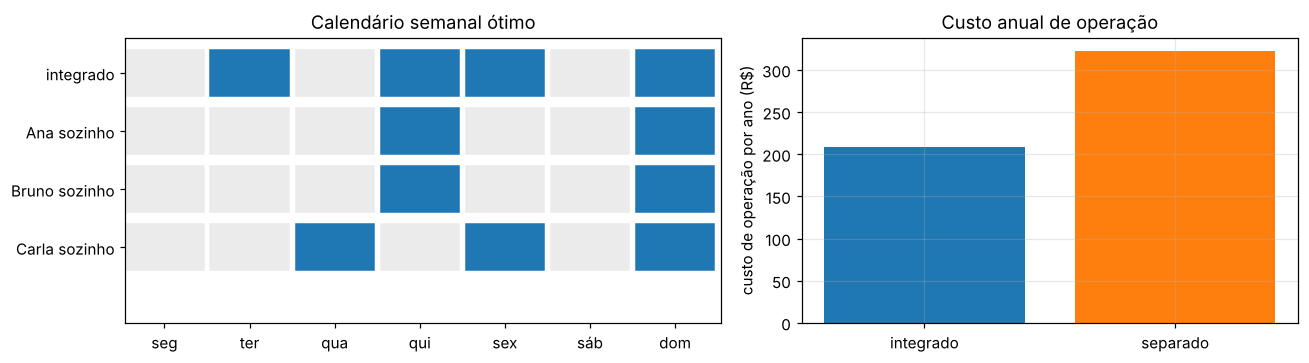

[figura salva] figuras_slides/slide11_pessoas_exigencia.png


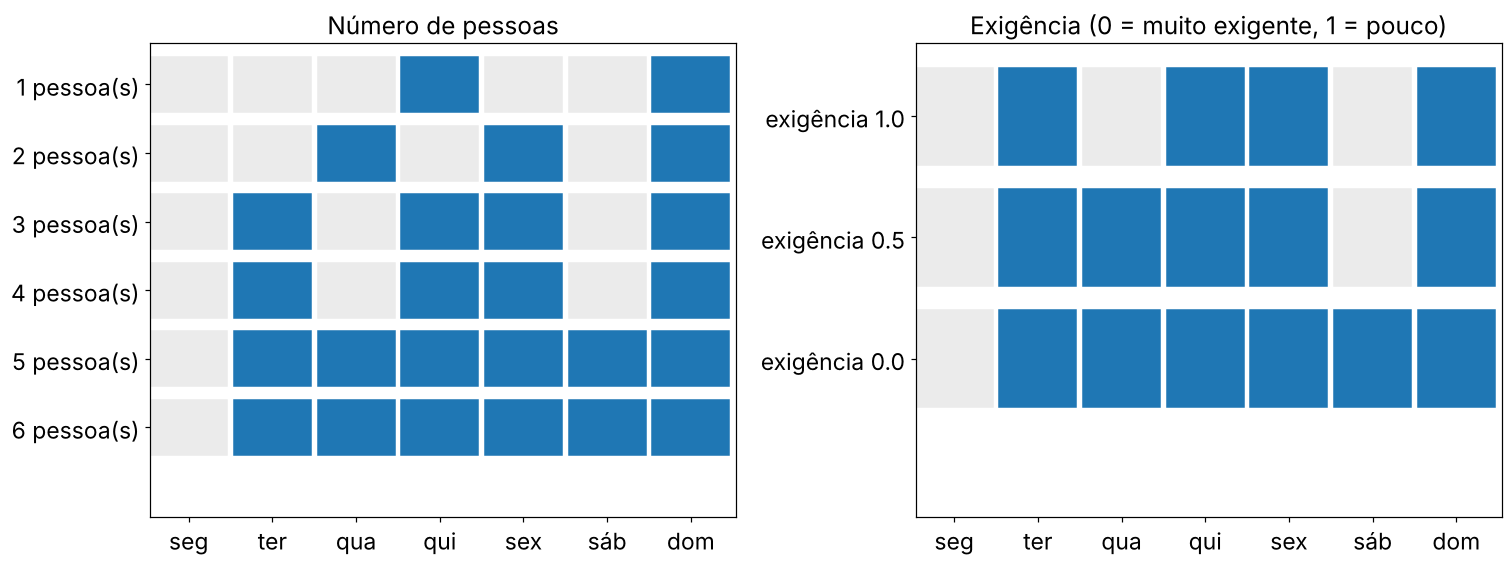

[figura salva] figuras_slides/slide12_custo_autonomia.png


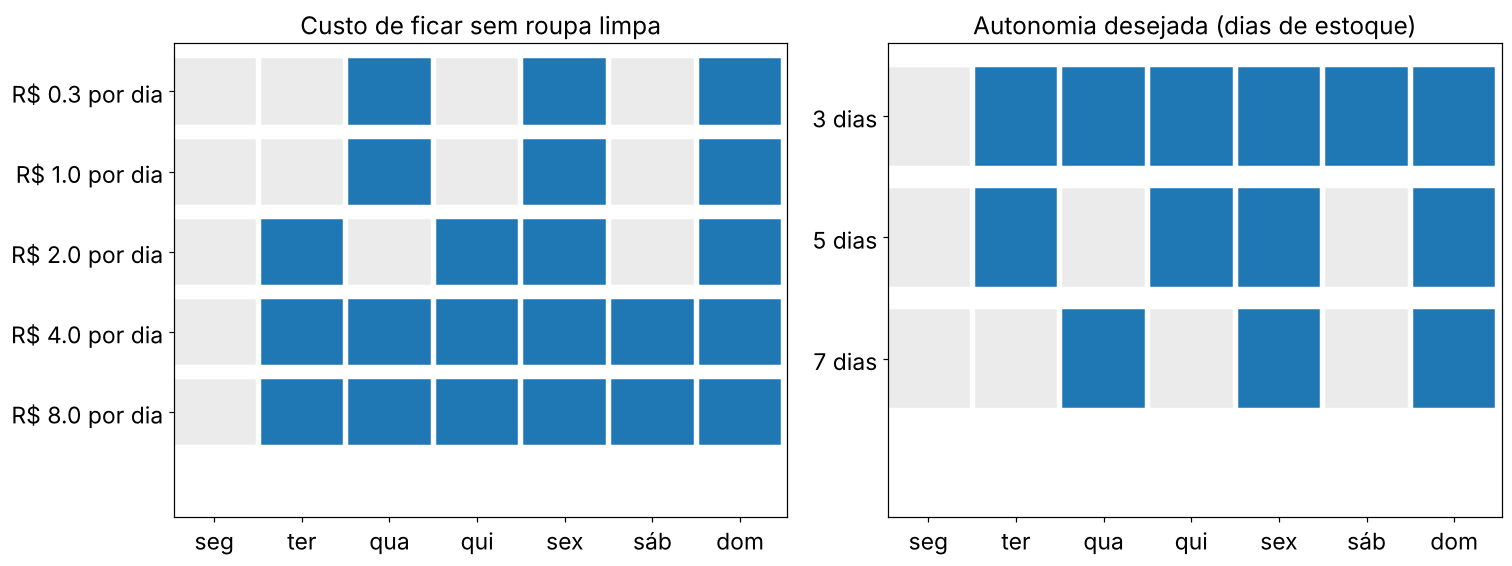

[figura salva] figuras_slides/slide13_apoio_ciclos_custo_satisfacao.png


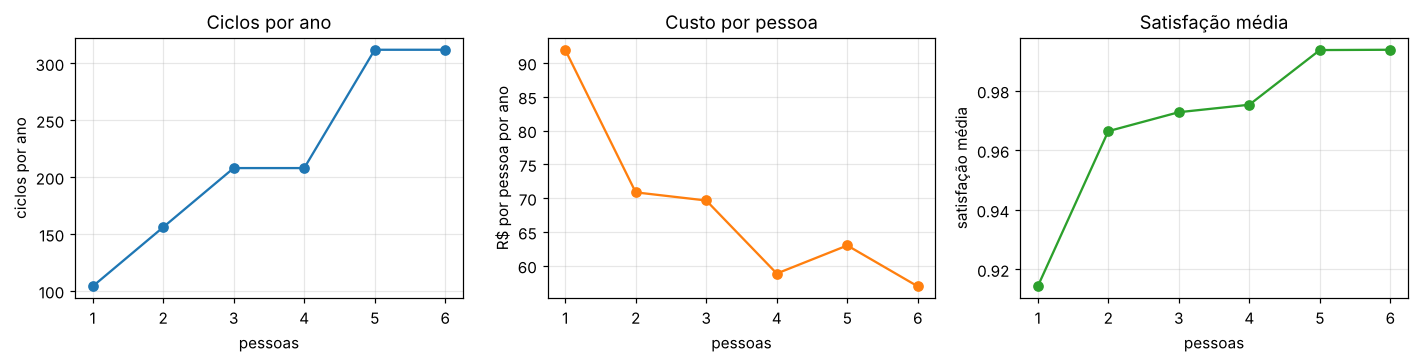

[figura salva] figuras_slides/slide13_mapa_pessoas_x_p.png


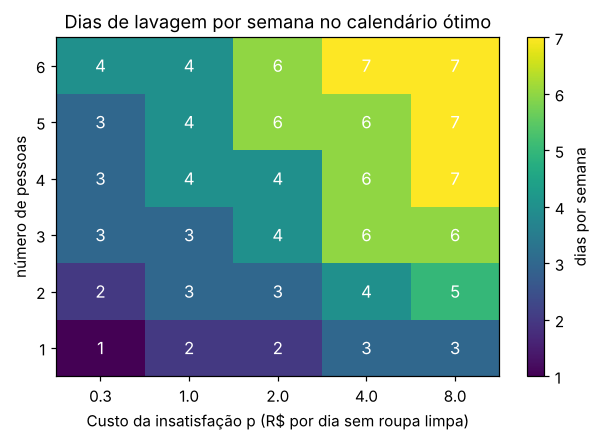

[figura salva] figuras_slides/slide14_uso_de_roupa.png


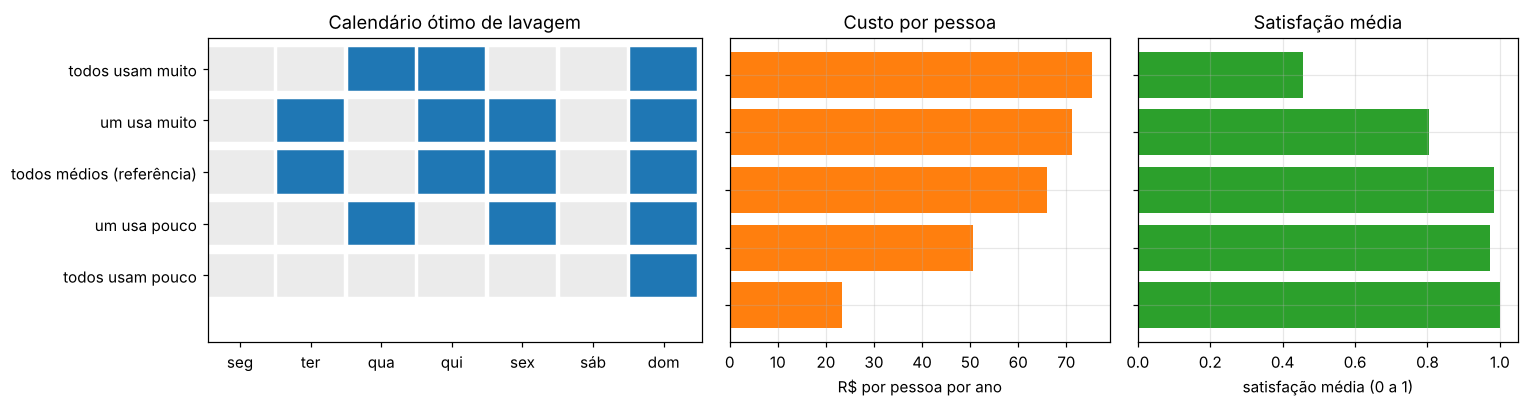

[figura salva] figuras_slides/slide14_guarda_roupa_maior.png


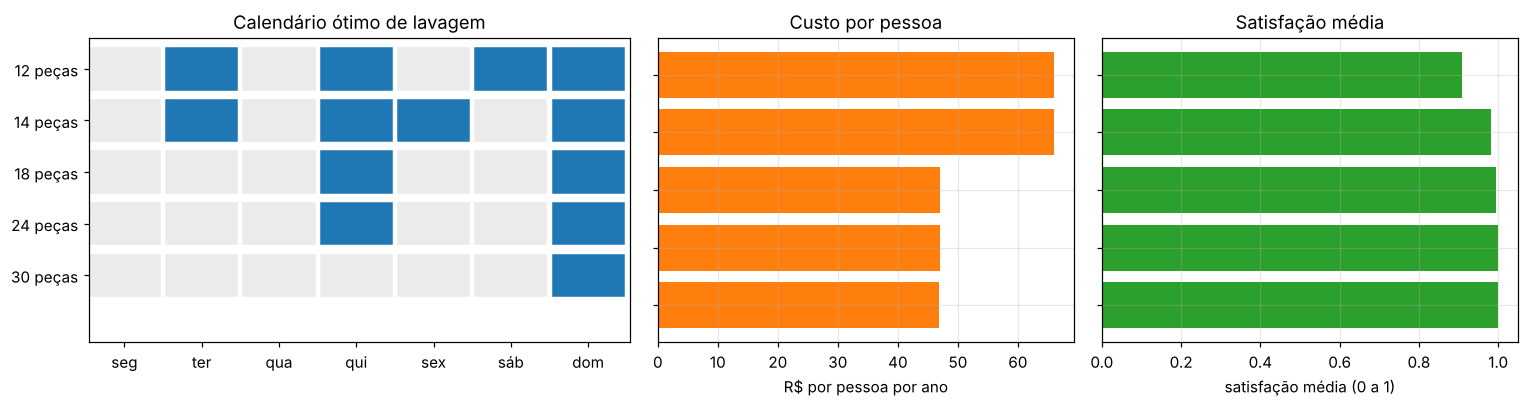

[figura salva] figuras_slides/slide16_perda_por_maquina.png


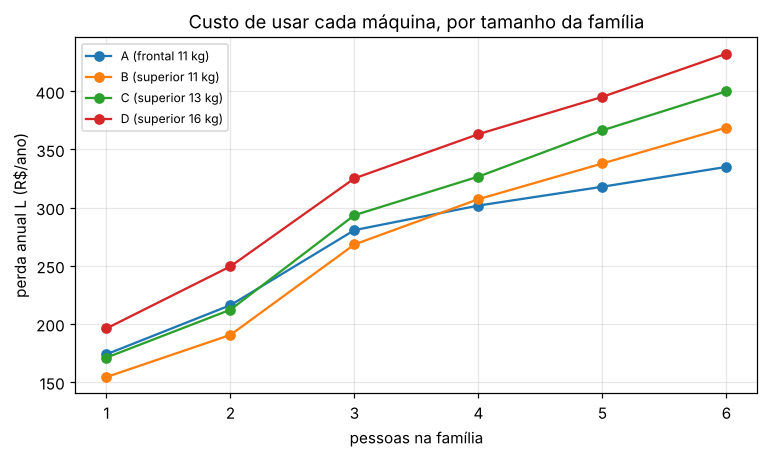

[figura salva] figuras_slides/apoio_perfis_de_roupa.png


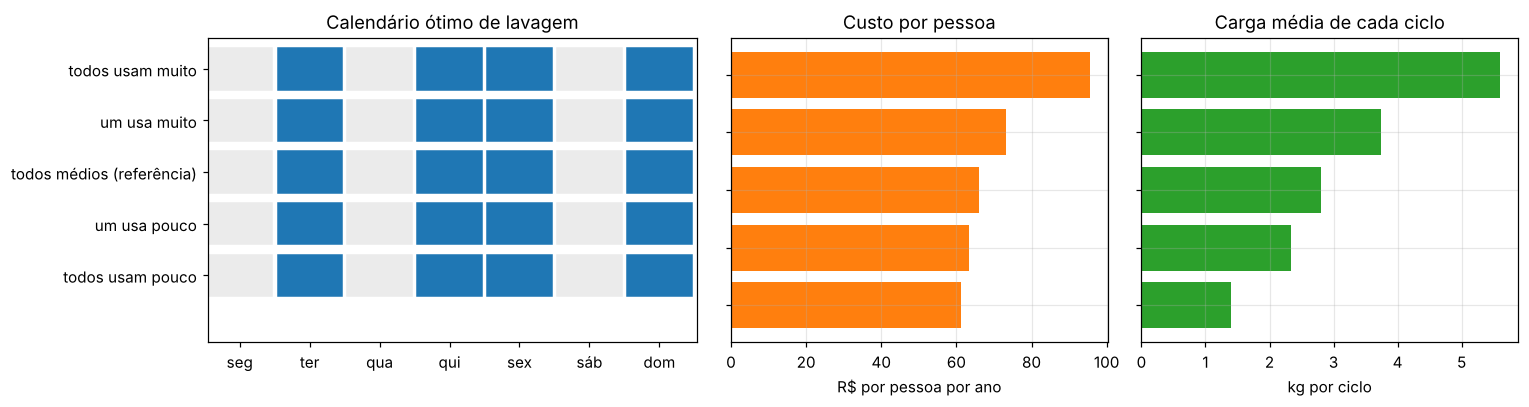

In [31]:
fig_slide09_calendarios_e_custo()             # Slide 9  : calendário ótimo e custo anual, integrado × separado
fig_slide11_pessoas_exigencia()               # Slide 11 : calendário ótimo × número de pessoas e exigência
fig_slide12_custo_autonomia()                 # Slide 12 : calendário ótimo × custo da insatisfação e autonomia
fig_slide13_apoio_ciclos_custo_satisfacao()   # Slide 13 : ciclos, custo por pessoa e satisfação × número de pessoas
fig_slide13_mapa_pessoas_x_p()                # Slide 13 : dias de lavagem por semana × (pessoas, p)
fig_slide14_uso_de_roupa()                    # Slide 14 : hábito de uso, mesmo guarda-roupa
fig_slide14_guarda_roupa_maior()              # Slide 14 : guarda-roupa maior, uso fixo
fig_slide16_perda_por_maquina()               # Slide 16 : perda anual de cada máquina × tamanho da família
fig_apoio_perfis_de_roupa()                   # sem slide : apoio (guarda-roupa proporcional ao uso)

## Referências ##

**Dados do modelo**
- Inmetro / Programa Brasileiro de Etiquetagem (2023). Tabela de lavadoras e secadoras automáticas de abertura frontal (edição de 19/06/2023).
- Idec. Faixas de consumo de energia de lavadoras por categoria (Inmetro). https://idec.org.br/print/24463
- Fichas técnicas de fabricantes e lojas das máquinas de abertura superior (listadas na seção "Fontes dos dados das máquinas").
- Águas do Rio. *Legislação e Tarifas*, https://www.aguasdorio.com.br/legislacao-e-tarifas/ (Região 1, Área A).
- ANEEL. Bandeira tarifária de novembro de 2026 (verde, anúncio de 30/10/2026); reajuste da Light (REH 3.571/2026).

**Método**
- Wagner & Whitin (1958), "Dynamic Version of the Economic Lot Size Model", *Management Science* 5(1), 89–96.
- Mohsenian-Rad & Leon-Garcia (2010), "Optimal Residential Load Control With Price Prediction in Real-Time Electricity Pricing Environments", *IEEE Trans. Smart Grid* 1(2), 120–133.

**Contexto (consumo residencial de água e energia)**
- Barreto, D. (2008). Perfil do consumo residencial e usos finais da água. *Ambiente Construído*, 8(2), 23-40.
- Estudo de caso: usos finais da água em uma residência em Joinville-SC (ENTAC).
- Cunha, K. Caracterização e monitoramento do consumo de água em habitações de interesse social (UFES).
- Teixeira, C. A.; Melo, A. P.; Fossati, M.; Lamberts, R. (2022). Bottom-up modelling of electricity end-use consumption of the residential sector in Brazil. *Ambiente Construído*, 22(3), 113-131. DOI 10.1590/s1678-86212022000300611.
- Trata Brasil / Ex Ante (2025). *Demanda futura por água em 2050*, seção 2.4 (consumo residencial de água em 2023).
- EPE. Resenha Mensal do Mercado de Energia Elétrica (2024) e Anuário Estatístico de Energia Elétrica.
- IBGE. PNAD Contínua 2019, *Características gerais dos domicílios e dos moradores*.
- Procel/Eletrobras. Pesquisa de Posse e Hábitos de Uso de Equipamentos Elétricos (PPH 2019).
